# WM811K — Notebook 3: Primary Training

This notebook is **execution-only** for the frozen WM811K spatial-information experiment. It does not redefine the cohort, splits, representations, preprocessing, model, class weights, seeds, or training hyperparameters.

## After a Colab runtime reset
1. Open this notebook in Google Colab.
2. Select a **GPU runtime** (T4 is sufficient).
3. Choose **Runtime → Run all**.
4. Cell 1 verifies and reconstructs the frozen experiment from Google Drive.
5. Cell 2 verifies completed runs, skips them, and resumes at the first unfinished `layout_only` run.

Completed runs are never silently overwritten. An interrupted run is archived and only that run restarts from epoch 1.

> Do **not** add the old cache-builder Cell 11A here. The cache was already created and verified once.


In [ ]:
# ============================================================
# CELL 1 — RECOVERY / BOOTSTRAP FROM FROZEN DRIVE FILES
# ============================================================
import os
os.environ["TF_DETERMINISTIC_OPS"] = "1"

from pathlib import Path
import hashlib, json, shutil
import numpy as np
import pandas as pd
import tensorflow as tf
from google.colab import drive

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

drive.mount("/content/drive", force_remount=False)

# ---------- Frozen fingerprints ----------
EXPECTED_METADATA_SHA256 = "e7ab1ee2c313336d20da855c98753dc483ef596cb72fb91961c592b6bc1c9195"
EXPECTED_REPRESENTATION_PROTOCOL_SHA256 = "521acba6f279b393ef3bfe47d134b2caddcd9d606b38fb353c8fa79a8ad25a8c"
EXPECTED_PREPROCESSING_PROTOCOL_SHA256 = "181061c977260e1a20546d02382fdbcceb15d39acd3d158ecab02d5e87db9804"
EXPECTED_EXPERIMENT_INPUT_PIPELINE_SHA256 = "4bb87c80ea23aadd4752de827e6721af43cd6b8b097060a9a9d28659ca79d06f"
EXPECTED_MODEL_TRAINING_PROTOCOL_SHA256 = "9f426f1774f19fdf4c6f92bc6eecf9f050437cbd92faddcd7b799f67c071bd42"
EXPECTED_PRETRAINING_EXPERIMENT_SHA256 = "e806023eb4544bf91f28605bce10f4032139b8ad7249d123c1e07453df04e5d0"

PROJECT_DIR = Path("/content/drive/MyDrive/WM811K_Spatial_Information_Audit")
FROZEN_DATA_DIR = PROJECT_DIR / "frozen_data"
EXPERIMENT_DIR = PROJECT_DIR / "experiments"
REP_DIR = EXPERIMENT_DIR / "representation_protocol"
PREP_DIR = EXPERIMENT_DIR / "preprocessing_protocol"
MODEL_DIR = EXPERIMENT_DIR / "model_training_protocol"
CACHE_DIR = EXPERIMENT_DIR / "execution_cache_160x160"


def sha256_file(path, chunk=8*1024*1024):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        while True:
            b=f.read(chunk)
            if not b: break
            h.update(b)
    return h.hexdigest()


def canonical_json_sha256(obj):
    txt=json.dumps(obj, sort_keys=True, separators=(",",":"))
    return hashlib.sha256(txt.encode("utf-8")).hexdigest()

# ---------- Verify frozen protocol hashes ----------
def read_hash(path):
    return path.read_text(encoding="utf-8").strip()

assert read_hash(REP_DIR/"FROZEN_representation_protocol_sha256.txt") == EXPECTED_REPRESENTATION_PROTOCOL_SHA256
assert read_hash(PREP_DIR/"FROZEN_preprocessing_protocol_sha256.txt") == EXPECTED_PREPROCESSING_PROTOCOL_SHA256
assert read_hash(MODEL_DIR/"FROZEN_model_training_protocol_sha256.txt") == EXPECTED_MODEL_TRAINING_PROTOCOL_SHA256
assert read_hash(MODEL_DIR/"FROZEN_pretraining_experiment_sha256.txt") == EXPECTED_PRETRAINING_EXPERIMENT_SHA256
print("PASS: frozen protocol hashes match.")

# ---------- Metadata ----------
metadata_path=FROZEN_DATA_DIR/"FROZEN_primary_clean_metadata.tsv"
assert sha256_file(metadata_path) == EXPECTED_METADATA_SHA256
metadata=pd.read_csv(metadata_path, sep="\t")
assert len(metadata)==25513

class_lookup=(metadata[["class_id","label"]].drop_duplicates().sort_values("class_id"))
assert class_lookup["class_id"].tolist()==list(range(8))
DEFECT_CLASSES=class_lookup["label"].tolist()
CLASS_TO_ID={label:i for i,label in enumerate(DEFECT_CLASSES)}

expected_counts={1:{"train":13794,"validation":3375,"test":8344},
                 2:{"train":13509,"validation":3465,"test":8539},
                 3:{"train":13598,"validation":3285,"test":8630}}
for fold in (1,2,3):
    assert metadata[f"role_outer_{fold}"].value_counts().to_dict()==expected_counts[fold]
print("PASS: metadata and frozen role counts match.")

# ---------- Model/training protocol ----------
training_protocol_path=MODEL_DIR/"FROZEN_model_training_protocol.json"
training_protocol=json.loads(training_protocol_path.read_text(encoding="utf-8"))
assert canonical_json_sha256(training_protocol)==EXPECTED_MODEL_TRAINING_PROTOCOL_SHA256

PRIMARY_REPRESENTATIONS=list(training_protocol["representations"])
MODEL_SEEDS=list(training_protocol["model_seeds"])
PRIMARY_INPUT_SHAPE=tuple(training_protocol["input_shape"])
BATCH_SIZE=int(training_protocol["batch_size"])
MAX_EPOCHS=int(training_protocol["maximum_epochs"])
INITIAL_LEARNING_RATE=float(training_protocol["initial_learning_rate"])
WEIGHT_DECAY=float(training_protocol["weight_decay"])
DROPOUT_RATE=float(training_protocol["classifier_head"]["dropout"])
EARLY_STOPPING_PATIENCE=int(training_protocol["early_stopping_patience_epochs"])
EARLY_STOPPING_MIN_DELTA=float(training_protocol["early_stopping_min_delta"])
MODEL_SELECTION_METRIC=training_protocol["checkpoint_selection_metric"]
PRIMARY_MODEL_PARAMETER_COUNT=int(training_protocol["parameter_count"])
assert PRIMARY_INPUT_SHAPE==(160,160,2)
assert BATCH_SIZE==64
assert MODEL_SEEDS==[42,123,456]
print("PASS: frozen training protocol loaded.")

# ---------- Class weights ----------
class_weights_path=MODEL_DIR/"FROZEN_training_class_weights.tsv"
assert sha256_file(class_weights_path)==training_protocol["class_weights_file_sha256"]
class_weight_table=pd.read_csv(class_weights_path, sep="\t")
FOLD_CLASS_WEIGHTS={}
for fold in (1,2,3):
    s=class_weight_table[class_weight_table.outer_fold==fold]
    FOLD_CLASS_WEIGHTS[fold]={int(r.class_id):float(r.class_weight) for r in s.itertuples(index=False)}

# ---------- Planned runs ----------
planned_runs=pd.read_csv(MODEL_DIR/"FROZEN_planned_primary_runs.csv")
assert len(planned_runs)==36

# ---------- Frozen 24-wafer sensitivity list ----------
prep_protocol=json.loads((PREP_DIR/"FROZEN_preprocessing_protocol.json").read_text(encoding="utf-8"))
oversized_path=PREP_DIR/prep_protocol["downscaled_wafer_list_file"]
assert sha256_file(oversized_path)==prep_protocol["downscaled_wafer_list_sha256"]
oversized_160=pd.read_csv(oversized_path, sep="\t")
assert len(oversized_160)==24

# ---------- Execution cache ----------
cache_manifest_path=CACHE_DIR/"execution_cache_manifest.json"
cache_manifest=json.loads(cache_manifest_path.read_text(encoding="utf-8"))
assert canonical_json_sha256(cache_manifest)==read_hash(CACHE_DIR/"execution_cache_manifest_sha256.txt")
assert cache_manifest["experiment_input_pipeline_sha256"]==EXPECTED_EXPERIMENT_INPUT_PIPELINE_SHA256
assert cache_manifest["model_training_protocol_sha256"]==EXPECTED_MODEL_TRAINING_PROTOCOL_SHA256
assert cache_manifest["pretraining_experiment_sha256"]==EXPECTED_PRETRAINING_EXPERIMENT_SHA256

LOCAL_CACHE_DIR=Path("/content/wm811k_execution_cache")
LOCAL_CACHE_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_CACHE_PATHS={}
print("="*78)
print("VERIFYING / COPYING MODEL-INPUT CACHE")
print("="*78)
for rep in PRIMARY_REPRESENTATIONS:
    rec=cache_manifest["files"][rep]
    src=CACHE_DIR/rec["filename"]
    assert sha256_file(src)==rec["sha256"]
    dst=LOCAL_CACHE_DIR/rec["filename"]
    ok=dst.exists() and dst.stat().st_size==src.stat().st_size
    if ok:
        ok=(sha256_file(dst)==rec["sha256"])
    if not ok:
        print(f"Copying {rep} to local runtime...")
        shutil.copy2(src,dst)
        assert sha256_file(dst)==rec["sha256"]
    else:
        print(f"Local {rep} cache already valid.")
    LOCAL_CACHE_PATHS[rep]=dst

PACK_BITORDER=cache_manifest["packbits_bitorder"]
FLAT_INPUT_BITS=int(cache_manifest["flat_binary_values_per_wafer"])
PACKED_BYTES_PER_WAFER=int(cache_manifest["packed_bytes_per_wafer"])
PACKED_INPUTS={}
for rep in PRIMARY_REPRESENTATIONS:
    mm=np.load(LOCAL_CACHE_PATHS[rep], mmap_mode="r", allow_pickle=False)
    assert mm.shape==(25513,PACKED_BYTES_PER_WAFER)
    PACKED_INPUTS[rep]=mm
print("PASS: all four packed input caches are verified and memory-mapped.")


def build_cached_array(positions, representation_name, chunk_size=256):
    positions=np.asarray(positions,dtype=np.int64)
    X=np.empty((len(positions),160,160,2),dtype=np.uint8)
    source=PACKED_INPUTS[representation_name]
    for start in range(0,len(positions),chunk_size):
        stop=min(start+chunk_size,len(positions))
        packed=np.asarray(source[positions[start:stop]],dtype=np.uint8)
        bits=np.unpackbits(packed,axis=1,count=FLAT_INPUT_BITS,bitorder=PACK_BITORDER)
        X[start:stop]=bits.reshape(-1,160,160,2)
    y=metadata.iloc[positions]["class_id"].astype(np.int32).to_numpy()
    assert np.all(X[:,:,:,1] <= X[:,:,:,0])
    if representation_name=="layout_only":
        assert int(X[:,:,:,1].sum())==0
    return X,y

# ---------- Exact frozen architecture ----------
def build_primary_cnn(seed):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(int(seed))
    inp=tf.keras.Input(shape=PRIMARY_INPUT_SHAPE,name="wafer_input")
    x=inp
    for block,filters in enumerate((16,32,64,128),start=1):
        x=tf.keras.layers.Conv2D(filters,3,padding="same",use_bias=False,kernel_initializer="he_normal",name=f"block{block}_conv1")(x)
        x=tf.keras.layers.BatchNormalization(name=f"block{block}_bn1")(x)
        x=tf.keras.layers.ReLU(name=f"block{block}_relu1")(x)
        x=tf.keras.layers.Conv2D(filters,3,padding="same",use_bias=False,kernel_initializer="he_normal",name=f"block{block}_conv2")(x)
        x=tf.keras.layers.BatchNormalization(name=f"block{block}_bn2")(x)
        x=tf.keras.layers.ReLU(name=f"block{block}_relu2")(x)
        x=tf.keras.layers.MaxPooling2D(2,name=f"block{block}_pool")(x)
    x=tf.keras.layers.Flatten(name="flatten_spatial_features")(x)
    x=tf.keras.layers.Dense(256,activation="relu",kernel_initializer="he_normal",name="dense_256")(x)
    x=tf.keras.layers.Dropout(DROPOUT_RATE,seed=int(seed),name="dropout")(x)
    out=tf.keras.layers.Dense(len(DEFECT_CLASSES),activation="softmax",name="class_probabilities")(x)
    model=tf.keras.Model(inp,out,name="WM811K_SpatialAudit_CNN")
    assert model.count_params()==PRIMARY_MODEL_PARAMETER_COUNT
    return model

# ---------- GPU ----------
gpus=tf.config.list_physical_devices("GPU")
if not gpus:
    raise RuntimeError("No GPU detected. Change Colab to a GPU runtime and Run all again.")

print("="*78)
print("RECOVERY COMPLETE")
print("="*78)
print("GPU:",gpus)
print("Wafers:",f"{len(metadata):,}")
print("Representations:",PRIMARY_REPRESENTATIONS)
print("Planned runs:",len(planned_runs))
print("Ready for the resume-safe training cell.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PASS: frozen protocol hashes match.
PASS: metadata and frozen role counts match.
PASS: frozen training protocol loaded.
VERIFYING / COPYING MODEL-INPUT CACHE
Local layout_only cache already valid.
Local global_shuffle cache already valid.
Local radial_shuffle cache already valid.
Local original cache already valid.
PASS: all four packed input caches are verified and memory-mapped.


RuntimeError: No GPU detected. Change Colab to a GPU runtime and Run all again.

In [ ]:
# ============================================================
# CELL 2 — RESUME-SAFE PRIMARY TRAINING RUNNER
# ============================================================
# Current phase: finish the 9 frozen layout_only runs.
# Completed runs are verified and skipped.
# Interrupted attempts are archived; only that run restarts.
# ============================================================
from datetime import datetime, timezone
import gc, hashlib, json, shutil, time, traceback
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support

RUN_ONLY_REPRESENTATION="radial_shuffle"
MAX_NEW_RUNS=None   # None = run every unfinished layout_only job
PRIMARY_RUNS_DIR=EXPERIMENT_DIR/"primary_runs"
INTERRUPTED_RUNS_DIR=PRIMARY_RUNS_DIR/"_interrupted_attempts"
PRIMARY_RUNS_DIR.mkdir(parents=True,exist_ok=True)
INTERRUPTED_RUNS_DIR.mkdir(parents=True,exist_ok=True)


def run_file_sha256(path, chunk=8*1024*1024):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        while True:
            b=f.read(chunk)
            if not b: break
            h.update(b)
    return h.hexdigest()


def validate_completed_run(run_spec):
    run_id=str(run_spec["run_id"])
    run_dir=PRIMARY_RUNS_DIR/run_id
    marker_path=run_dir/"RUN_COMPLETE.json"
    if not marker_path.exists(): return False
    try:
        marker=json.loads(marker_path.read_text(encoding="utf-8"))
        assert marker["run_id"]==run_id and marker["status"]=="COMPLETE"
        assert marker["representation"]==str(run_spec["representation"])
        assert int(marker["outer_fold"])==int(run_spec["outer_fold"])
        assert int(marker["model_seed"])==int(run_spec["model_seed"])
        assert marker["model_training_protocol_sha256"]==EXPECTED_MODEL_TRAINING_PROTOCOL_SHA256
        summary_path=run_dir/marker["summary_file"]
        summary=json.loads(summary_path.read_text(encoding="utf-8"))
        assert summary["run_id"]==run_id
        assert summary["model_training_protocol_sha256"]==EXPECTED_MODEL_TRAINING_PROTOCOL_SHA256
        assert summary["pretraining_experiment_sha256"]==EXPECTED_PRETRAINING_EXPERIMENT_SHA256
        for fn,h in ((summary["best_checkpoint_file"],summary["best_checkpoint_sha256"]),
                     (summary["training_history_file"],summary["training_history_sha256"]),
                     (summary["test_predictions_file"],summary["test_predictions_sha256"])):
            p=run_dir/fn
            assert p.exists() and run_file_sha256(p)==h
        return True
    except Exception as exc:
        raise RuntimeError(f"Completed-run verification FAILED for {run_id}. Do not overwrite it automatically.\n{exc}")


def prepare_fresh_run_directory(run_id):
    run_dir=PRIMARY_RUNS_DIR/run_id
    if run_dir.exists() and list(run_dir.iterdir()):
        stamp=datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_UTC")
        archived=INTERRUPTED_RUNS_DIR/f"{run_id}__INTERRUPTED__{stamp}"
        shutil.move(str(run_dir),str(archived))
        print("Preserved interrupted attempt:",archived)
    elif run_dir.exists():
        run_dir.rmdir()
    run_dir.mkdir(parents=True,exist_ok=False)
    return run_dir


class ValidationMacroF1(tf.keras.callbacks.Callback):
    def __init__(self,x_validation,y_validation,batch_size):
        super().__init__()
        self.x_validation=x_validation
        self.y_validation=np.asarray(y_validation,dtype=np.int32)
        self.batch_size=int(batch_size)
    def on_epoch_end(self,epoch,logs=None):
        logs={} if logs is None else logs
        prob=self.model.predict(self.x_validation,batch_size=self.batch_size,verbose=0)
        pred=np.argmax(prob,axis=1)
        score=float(f1_score(self.y_validation,pred,labels=np.arange(len(DEFECT_CLASSES)),average="macro",zero_division=0))
        logs[MODEL_SELECTION_METRIC]=score
        print(f"    {MODEL_SELECTION_METRIC}: {score:.6f}")


def calculate_classification_metrics(y_true,y_pred):
    y_true=np.asarray(y_true,dtype=np.int32); y_pred=np.asarray(y_pred,dtype=np.int32)
    labels=np.arange(len(DEFECT_CLASSES))
    precision,recall,class_f1,support=precision_recall_fscore_support(y_true,y_pred,labels=labels,zero_division=0)
    summary={
        "n_samples":int(len(y_true)),
        "accuracy":float(accuracy_score(y_true,y_pred)),
        "balanced_accuracy":float(balanced_accuracy_score(y_true,y_pred)),
        "macro_f1":float(f1_score(y_true,y_pred,labels=labels,average="macro",zero_division=0)),
        "weighted_f1":float(f1_score(y_true,y_pred,labels=labels,average="weighted",zero_division=0)),
    }
    per_class=pd.DataFrame({"class_id":labels,"label":DEFECT_CLASSES,"precision":precision,"recall":recall,"f1":class_f1,"support":support.astype(int)})
    cm=confusion_matrix(y_true,y_pred,labels=labels)
    return summary,per_class,cm


def execute_primary_run(run_spec):
    RUN_ID=str(run_spec["run_id"]); REPRESENTATION_NAME=str(run_spec["representation"])
    OUTER_FOLD=int(run_spec["outer_fold"]); MODEL_SEED=int(run_spec["model_seed"])
    print("\n"+"#"*78); print("# STARTING PRIMARY RUN"); print("#"*78)
    print("Run:",RUN_ID," | fold:",OUTER_FOLD," | seed:",MODEL_SEED)
    RUN_DIR=prepare_fresh_run_directory(RUN_ID)
    COMPLETE_MARKER=RUN_DIR/"RUN_COMPLETE.json"
    BEST_CHECKPOINT_PATH=RUN_DIR/"best_model.keras"
    role=f"role_outer_{OUTER_FOLD}"
    train_positions=np.flatnonzero((metadata[role]=="train").to_numpy())
    val_positions=np.flatnonzero((metadata[role]=="validation").to_numpy())
    assert not(set(train_positions.tolist()) & set(val_positions.tolist()))
    print(f"Training={len(train_positions):,}; validation={len(val_positions):,}; TEST not built yet.")
    X_train,y_train=build_cached_array(train_positions,REPRESENTATION_NAME)
    X_val,y_val=build_cached_array(val_positions,REPRESENTATION_NAME)

    model=build_primary_cnn(MODEL_SEED)
    optimizer=tf.keras.optimizers.AdamW(learning_rate=INITIAL_LEARNING_RATE,weight_decay=WEIGHT_DECAY)
    model.compile(optimizer=optimizer,loss=tf.keras.losses.SparseCategoricalCrossentropy(),metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")])
    f1cb=ValidationMacroF1(X_val,y_val,BATCH_SIZE)
    callbacks=[
        f1cb,
        tf.keras.callbacks.ModelCheckpoint(str(BEST_CHECKPOINT_PATH),monitor=MODEL_SELECTION_METRIC,mode="max",save_best_only=True,verbose=1),
        tf.keras.callbacks.EarlyStopping(monitor=MODEL_SELECTION_METRIC,mode="max",patience=EARLY_STOPPING_PATIENCE,min_delta=EARLY_STOPPING_MIN_DELTA,restore_best_weights=True,verbose=1),
        tf.keras.callbacks.TerminateOnNaN(),
    ]
    started=datetime.now(timezone.utc).isoformat()
    (RUN_DIR/"run_config.json").write_text(json.dumps({
        "run_id":RUN_ID,"representation":REPRESENTATION_NAME,"outer_fold":OUTER_FOLD,"model_seed":MODEL_SEED,
        "training_wafers":int(len(train_positions)),"validation_wafers":int(len(val_positions)),
        "batch_size":BATCH_SIZE,"maximum_epochs":MAX_EPOCHS,"initial_learning_rate":INITIAL_LEARNING_RATE,
        "weight_decay":WEIGHT_DECAY,"model_selection_metric":MODEL_SELECTION_METRIC,
        "test_inputs_constructed_before_model_selection":False,
        "execution_source":"verified bit-packed frozen 160x160 model-input cache",
        "model_training_protocol_sha256":EXPECTED_MODEL_TRAINING_PROTOCOL_SHA256,
        "pretraining_experiment_sha256":EXPECTED_PRETRAINING_EXPERIMENT_SHA256,
        "run_started_utc":started},indent=2,sort_keys=True),encoding="utf-8")

    t0=time.time()
    hist=model.fit(X_train,y_train,validation_data=(X_val,y_val),epochs=MAX_EPOCHS,batch_size=BATCH_SIZE,
                   class_weight=FOLD_CLASS_WEIGHTS[OUTER_FOLD],callbacks=callbacks,shuffle=True,verbose=2)
    elapsed=time.time()-t0
    hdf=pd.DataFrame(hist.history); hdf.insert(0,"epoch",np.arange(1,len(hdf)+1))
    assert MODEL_SELECTION_METRIC in hdf.columns
    bi=int(np.argmax(hdf[MODEL_SELECTION_METRIC].to_numpy()))
    best_epoch=int(hdf.iloc[bi]["epoch"]); best_val=float(hdf.iloc[bi][MODEL_SELECTION_METRIC])
    history_path=RUN_DIR/"training_history.csv"; hdf.to_csv(history_path,index=False)
    assert BEST_CHECKPOINT_PATH.exists()
    print(f"Best epoch={best_epoch}; best validation macro-F1={best_val:.6f}")
    print("MODEL SELECTION COMPLETE. Outer test data may now be accessed.")

    del model,optimizer,callbacks; tf.keras.backend.clear_session(); gc.collect()
    best_model=tf.keras.models.load_model(BEST_CHECKPOINT_PATH)
    vp=best_model.predict(X_val,batch_size=BATCH_SIZE,verbose=0)
    reload_val=float(f1_score(y_val,np.argmax(vp,axis=1),labels=np.arange(len(DEFECT_CLASSES)),average="macro",zero_division=0))
    assert np.isclose(reload_val,best_val,atol=1e-6)
    del X_train,y_train,X_val,y_val,vp; gc.collect()

    # TEST is built only after model selection.
    test_positions=np.flatnonzero((metadata[role]=="test").to_numpy())
    X_test,y_test=build_cached_array(test_positions,REPRESENTATION_NAME)
    prob=best_model.predict(X_test,batch_size=BATCH_SIZE,verbose=1)
    pred=np.argmax(prob,axis=1).astype(np.int32)
    metrics,per_class,cm=calculate_classification_metrics(y_test,pred)

    downscaled=set(oversized_160["orig_index"].astype(int).tolist())
    test_orig=metadata.iloc[test_positions]["orig_index"].astype(int).to_numpy()
    is_down=np.asarray([int(x) in downscaled for x in test_orig],dtype=bool)
    expected_down={1:10,2:6,3:8}; assert int(is_down.sum())==expected_down[OUTER_FOLD]
    sens_metrics,sens_per_class,sens_cm=calculate_classification_metrics(y_test[~is_down],pred[~is_down])

    per_class.to_csv(RUN_DIR/"test_per_class_metrics.csv",index=False)
    sens_per_class.to_csv(RUN_DIR/"test_per_class_metrics_excluding_downscaled.csv",index=False)
    pd.DataFrame(cm,index=[f"true_{x}" for x in DEFECT_CLASSES],columns=[f"pred_{x}" for x in DEFECT_CLASSES]).to_csv(RUN_DIR/"test_confusion_matrix.csv")
    pd.DataFrame(sens_cm,index=[f"true_{x}" for x in DEFECT_CLASSES],columns=[f"pred_{x}" for x in DEFECT_CLASSES]).to_csv(RUN_DIR/"test_confusion_matrix_excluding_downscaled.csv")

    tm=metadata.iloc[test_positions].reset_index(drop=True)
    pt=pd.DataFrame({
        "position":test_positions.astype(int),"orig_index":tm["orig_index"].astype(int),"lotName":tm["lotName"].astype(str),
        "strict_group":tm["strict_group"].astype(str),"true_class_id":y_test.astype(int),
        "true_label":[DEFECT_CLASSES[int(i)] for i in y_test],"predicted_class_id":pred.astype(int),
        "predicted_label":[DEFECT_CLASSES[int(i)] for i in pred],"correct":y_test==pred,"downscaled_at_160":is_down})
    for cid,label in enumerate(DEFECT_CLASSES):
        pt[f"prob_{label.lower().replace('-','_').replace(' ','_')}"]=prob[:,cid]
    prediction_path=RUN_DIR/"test_predictions.csv"; pt.to_csv(prediction_path,index=False)

    finished=datetime.now(timezone.utc).isoformat()
    summary={
        "run_id":RUN_ID,"scientific_primary_run":True,"representation":REPRESENTATION_NAME,"outer_fold":OUTER_FOLD,"model_seed":MODEL_SEED,
        "training_wafers":int(len(train_positions)),"validation_wafers":int(len(val_positions)),"test_wafers":int(len(test_positions)),
        "epochs_completed":int(len(hdf)),"best_epoch":best_epoch,"best_validation_macro_f1":best_val,
        "training_elapsed_seconds":float(elapsed),"primary_test_metrics":metrics,"downscaled_test_wafers":int(is_down.sum()),
        "sensitivity_test_metrics_excluding_downscaled":sens_metrics,"best_checkpoint_file":BEST_CHECKPOINT_PATH.name,
        "best_checkpoint_sha256":run_file_sha256(BEST_CHECKPOINT_PATH),"training_history_file":history_path.name,
        "training_history_sha256":run_file_sha256(history_path),"test_predictions_file":prediction_path.name,
        "test_predictions_sha256":run_file_sha256(prediction_path),"model_training_protocol_sha256":EXPECTED_MODEL_TRAINING_PROTOCOL_SHA256,
        "pretraining_experiment_sha256":EXPECTED_PRETRAINING_EXPERIMENT_SHA256,
        "test_inputs_constructed_only_after_model_selection":True,"execution_source":"verified bit-packed frozen 160x160 model-input cache",
        "run_started_utc":started,"run_finished_utc":finished}
    summary_path=RUN_DIR/"run_summary.json"; summary_path.write_text(json.dumps(summary,indent=2,sort_keys=True),encoding="utf-8")
    COMPLETE_MARKER.write_text(json.dumps({"run_id":RUN_ID,"status":"COMPLETE","representation":REPRESENTATION_NAME,
                                           "outer_fold":OUTER_FOLD,"model_seed":MODEL_SEED,"summary_file":summary_path.name,
                                           "completed_utc":finished,"model_training_protocol_sha256":EXPECTED_MODEL_TRAINING_PROTOCOL_SHA256},indent=2,sort_keys=True),encoding="utf-8")
    print("="*78); print("RUN COMPLETE",RUN_ID)
    print(f"TEST macro-F1={metrics['macro_f1']:.6f}; balanced acc={metrics['balanced_accuracy']:.6f}; accuracy={metrics['accuracy']:.6f}")
    print(f"Sensitivity macro-F1={sens_metrics['macro_f1']:.6f}; RUN_COMPLETE written.")
    del X_test,y_test,prob,pred,best_model; tf.keras.backend.clear_session(); gc.collect()
    return summary

# ---------- Resume loop ----------
target_runs=planned_runs[planned_runs.representation==RUN_ONLY_REPRESENTATION].reset_index(drop=True)
print("="*78); print("RESUME-SAFE RUNNER"); print("="*78)
print("Target representation:",RUN_ONLY_REPRESENTATION," | runs:",len(target_runs))
completed_before=0; newly_completed=0
for _,run_spec in target_runs.iterrows():
    rid=str(run_spec["run_id"])
    if validate_completed_run(run_spec):
        completed_before+=1; print("SKIP — already complete and verified:",rid); continue
    if MAX_NEW_RUNS is not None and newly_completed>=MAX_NEW_RUNS: break
    try:
        execute_primary_run(run_spec); newly_completed+=1
    except Exception:
        print("\n"+"="*78); print("RUN FAILED:",rid); print("="*78); traceback.print_exc()
        print("Partial directory preserved. Next invocation will archive it and restart only this run from epoch 1.")
        raise

status=[]
for _,r in target_runs.iterrows():
    status.append({"run_id":str(r.run_id),"representation":str(r.representation),"outer_fold":int(r.outer_fold),
                   "model_seed":int(r.model_seed),"status":"COMPLETE" if validate_completed_run(r) else "NOT_COMPLETE"})
execution_status=pd.DataFrame(status)
status_path=PRIMARY_RUNS_DIR/f"execution_status_{RUN_ONLY_REPRESENTATION}.csv"
execution_status.to_csv(status_path,index=False)
print("\n"+"="*78); print("RESUME-SAFE RUNNER FINISHED"); print("="*78)
display(execution_status)
print("Complete:",int((execution_status.status=="COMPLETE").sum()),"/",len(execution_status))
print("Already complete when this invocation began:",completed_before)
print("Newly completed this invocation:",newly_completed)
print("Status saved to:",status_path)


RESUME-SAFE RUNNER
Target representation: radial_shuffle  | runs: 9
SKIP — already complete and verified: radial_shuffle__fold1__seed42
SKIP — already complete and verified: radial_shuffle__fold1__seed123
SKIP — already complete and verified: radial_shuffle__fold1__seed456
SKIP — already complete and verified: radial_shuffle__fold2__seed42
SKIP — already complete and verified: radial_shuffle__fold2__seed123
SKIP — already complete and verified: radial_shuffle__fold2__seed456
SKIP — already complete and verified: radial_shuffle__fold3__seed42
SKIP — already complete and verified: radial_shuffle__fold3__seed123
SKIP — already complete and verified: radial_shuffle__fold3__seed456

RESUME-SAFE RUNNER FINISHED


,run_id,representation,outer_fold,model_seed,status
0,radial_shuffle__fold1__seed42,radial_shuffle,1,42,COMPLETE
1,radial_shuffle__fold1__seed123,radial_shuffle,1,123,COMPLETE
2,radial_shuffle__fold1__seed456,radial_shuffle,1,456,COMPLETE
3,radial_shuffle__fold2__seed42,radial_shuffle,2,42,COMPLETE
4,radial_shuffle__fold2__seed123,radial_shuffle,2,123,COMPLETE
5,radial_shuffle__fold2__seed456,radial_shuffle,2,456,COMPLETE
6,radial_shuffle__fold3__seed42,radial_shuffle,3,42,COMPLETE
7,radial_shuffle__fold3__seed123,radial_shuffle,3,123,COMPLETE
8,radial_shuffle__fold3__seed456,radial_shuffle,3,456,COMPLETE


Complete: 9 / 9
Already complete when this invocation began: 9
Newly completed this invocation: 0
Status saved to: /content/drive/MyDrive/WM811K_Spatial_Information_Audit/experiments/primary_runs/execution_status_radial_shuffle.csv


In [ ]:
# ============================================================
# NOTEBOOK 3 — CELL 3
# AGGREGATE ALL 9 COMPLETED layout_only RUNS
# ============================================================
#
# PURPOSE
# -------
#
# We have completed:
#
#       3 outer folds
#       x
#       3 model seeds
#
#       = 9 layout_only runs
#
#
# This cell summarizes those results WITHOUT training anything.
#
#
# THREE LEVELS OF SUMMARY
# -----------------------
#
# 1. Individual run table
#
#       fold 1 seed 42
#       fold 1 seed 123
#       ...
#       fold 3 seed 456
#
#
# 2. Fold-level summary
#
#       Average the 3 seeds within each outer fold.
#
# This tells us how much performance changes because of
# different held-out production groups.
#
#
# 3. POOLED OUT-OF-FOLD SUMMARY
#
# For a particular seed:
#
#       Fold 1 test predictions
#       +
#       Fold 2 test predictions
#       +
#       Fold 3 test predictions
#
# cover all 25,513 wafers exactly once.
#
# So for each seed we can calculate one whole-cohort
# out-of-fold result.
#
#
# IMPORTANT
# ---------
#
# These are descriptive summaries of the already-frozen
# experiment.
#
# They must NOT be used to alter:
#
#       model architecture
#       hyperparameters
#       preprocessing
#       splits
#       seeds
#
# ============================================================


from pathlib import Path

import json

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)


# ============================================================
# 0. SAFETY CHECKS
# ============================================================

required_variables = [
    "planned_runs",
    "DEFECT_CLASSES",
    "MODEL_SEEDS",
    "EXPERIMENT_DIR",
    "EXPECTED_MODEL_TRAINING_PROTOCOL_SHA256",
    "EXPECTED_PRETRAINING_EXPERIMENT_SHA256"
]


missing = [
    name
    for name in required_variables
    if name not in globals()
]


if missing:

    raise RuntimeError(
        "Missing required recovery state:\n\n"
        +
        "\n".join(missing)
        +
        "\n\nRun Recovery Cell R1 first."
    )


TARGET_REPRESENTATION = (
    "layout_only"
)


PRIMARY_RUNS_DIR = (
    EXPERIMENT_DIR
    /
    "primary_runs"
)


AGGREGATE_DIR = (
    PRIMARY_RUNS_DIR
    /
    "aggregate_layout_only"
)


AGGREGATE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 1. IDENTIFY THE 9 FROZEN layout_only RUNS
# ============================================================

layout_runs = (

    planned_runs[
        planned_runs[
            "representation"
        ]
        ==
        TARGET_REPRESENTATION
    ]

    .copy()

    .sort_values(
        [
            "outer_fold",
            "model_seed"
        ]
    )

    .reset_index(
        drop=True
    )
)


assert len(
    layout_runs
) == 9


print("=" * 78)
print("LAYOUT-ONLY AGGREGATION")
print("=" * 78)

print()

print(
    "Frozen runs expected:",
    len(
        layout_runs
    )
)

print()


# ============================================================
# 2. READ AND VERIFY EVERY RUN SUMMARY
# ============================================================

run_rows = []


for run_spec in layout_runs.itertuples(
    index=False
):

    run_id = str(
        run_spec.run_id
    )


    run_dir = (
        PRIMARY_RUNS_DIR
        /
        run_id
    )


    marker_path = (
        run_dir
        /
        "RUN_COMPLETE.json"
    )


    summary_path = (
        run_dir
        /
        "run_summary.json"
    )


    prediction_path = (
        run_dir
        /
        "test_predictions.csv"
    )


    if not marker_path.exists():

        raise RuntimeError(
            f"Missing RUN_COMPLETE marker:\n{run_id}"
        )


    if not summary_path.exists():

        raise RuntimeError(
            f"Missing run_summary.json:\n{run_id}"
        )


    if not prediction_path.exists():

        raise RuntimeError(
            f"Missing test_predictions.csv:\n{run_id}"
        )


    with open(
        marker_path,
        "r"
    ) as f:

        marker = json.load(
            f
        )


    with open(
        summary_path,
        "r"
    ) as f:

        summary = json.load(
            f
        )


    # --------------------------------------------------------
    # Identity checks
    # --------------------------------------------------------

    assert (
        marker[
            "status"
        ]
        ==
        "COMPLETE"
    )


    assert (
        marker[
            "run_id"
        ]
        ==
        run_id
    )


    assert (
        summary[
            "run_id"
        ]
        ==
        run_id
    )


    assert (
        summary[
            "representation"
        ]
        ==
        TARGET_REPRESENTATION
    )


    assert (
        int(
            summary[
                "outer_fold"
            ]
        )
        ==
        int(
            run_spec.outer_fold
        )
    )


    assert (
        int(
            summary[
                "model_seed"
            ]
        )
        ==
        int(
            run_spec.model_seed
        )
    )


    # --------------------------------------------------------
    # Scientific protocol checks
    # --------------------------------------------------------

    assert (
        summary[
            "model_training_protocol_sha256"
        ]
        ==
        EXPECTED_MODEL_TRAINING_PROTOCOL_SHA256
    )


    assert (
        summary[
            "pretraining_experiment_sha256"
        ]
        ==
        EXPECTED_PRETRAINING_EXPERIMENT_SHA256
    )


    primary_metrics = (
        summary[
            "primary_test_metrics"
        ]
    )


    sensitivity_metrics = (
        summary[
            "sensitivity_test_metrics_excluding_downscaled"
        ]
    )


    run_rows.append({

        "run_id":
            run_id,

        "outer_fold":
            int(
                summary[
                    "outer_fold"
                ]
            ),

        "model_seed":
            int(
                summary[
                    "model_seed"
                ]
            ),

        "epochs_completed":
            int(
                summary[
                    "epochs_completed"
                ]
            ),

        "best_epoch":
            int(
                summary[
                    "best_epoch"
                ]
            ),

        "best_validation_macro_f1":
            float(
                summary[
                    "best_validation_macro_f1"
                ]
            ),

        "test_n":
            int(
                primary_metrics[
                    "n_samples"
                ]
            ),

        "test_macro_f1":
            float(
                primary_metrics[
                    "macro_f1"
                ]
            ),

        "test_balanced_accuracy":
            float(
                primary_metrics[
                    "balanced_accuracy"
                ]
            ),

        "test_accuracy":
            float(
                primary_metrics[
                    "accuracy"
                ]
            ),

        "test_weighted_f1":
            float(
                primary_metrics[
                    "weighted_f1"
                ]
            ),

        "downscaled_test_wafers":
            int(
                summary[
                    "downscaled_test_wafers"
                ]
            ),

        "sensitivity_n":
            int(
                sensitivity_metrics[
                    "n_samples"
                ]
            ),

        "sensitivity_macro_f1":
            float(
                sensitivity_metrics[
                    "macro_f1"
                ]
            ),

        "sensitivity_balanced_accuracy":
            float(
                sensitivity_metrics[
                    "balanced_accuracy"
                ]
            ),

        "sensitivity_accuracy":
            float(
                sensitivity_metrics[
                    "accuracy"
                ]
            ),

        "training_minutes":
            float(
                summary[
                    "training_elapsed_seconds"
                ]
                /
                60.0
            )
    })


run_results = pd.DataFrame(
    run_rows
)


run_results = (
    run_results
    .sort_values(
        [
            "outer_fold",
            "model_seed"
        ]
    )
    .reset_index(
        drop=True
    )
)


assert len(
    run_results
) == 9


assert (
    run_results[
        "run_id"
    ].nunique()
    ==
    9
)


print(
    "PASS: all 9 layout_only runs are complete "
    "and use the frozen protocols."
)

print()


# ============================================================
# 3. SHOW THE 9 INDIVIDUAL RESULTS
# ============================================================

print("=" * 78)
print("INDIVIDUAL FOLD x SEED RESULTS")
print("=" * 78)

display(
    run_results[
        [
            "run_id",
            "outer_fold",
            "model_seed",
            "epochs_completed",
            "best_epoch",
            "best_validation_macro_f1",
            "test_macro_f1",
            "test_balanced_accuracy",
            "test_accuracy",
            "test_weighted_f1",
            "sensitivity_macro_f1",
            "training_minutes"
        ]
    ]
)

print()


# ============================================================
# 4. SIMPLE 9-RUN DESCRIPTIVE SUMMARY
#
# Useful, but remember that the three seeds within one fold
# share the same test wafers.
# ============================================================

summary_metrics = [
    "best_validation_macro_f1",
    "test_macro_f1",
    "test_balanced_accuracy",
    "test_accuracy",
    "test_weighted_f1",
    "sensitivity_macro_f1"
]


nine_run_summary_rows = []


for metric in summary_metrics:

    values = (
        run_results[
            metric
        ]
        .to_numpy(
            dtype=np.float64
        )
    )


    nine_run_summary_rows.append({

        "metric":
            metric,

        "mean":
            float(
                values.mean()
            ),

        "std":
            float(
                values.std(
                    ddof=1
                )
            ),

        "minimum":
            float(
                values.min()
            ),

        "maximum":
            float(
                values.max()
            )
    })


nine_run_summary = pd.DataFrame(
    nine_run_summary_rows
)


print("=" * 78)
print("DESCRIPTIVE SUMMARY ACROSS ALL 9 RUNS")
print("=" * 78)

display(
    nine_run_summary
)

print()


# ============================================================
# 5. FOLD-LEVEL SUMMARY
#
# Average the three random seeds inside each fold.
#
# This separates:
#
#       seed variability
#
# from
#
#       variability caused by different outer test groups.
# ============================================================

fold_summary = (

    run_results

    .groupby(
        "outer_fold",
        as_index=False
    )

    .agg(

        seed_runs=(
            "model_seed",
            "count"
        ),

        mean_validation_macro_f1=(
            "best_validation_macro_f1",
            "mean"
        ),

        std_validation_macro_f1=(
            "best_validation_macro_f1",
            "std"
        ),

        mean_test_macro_f1=(
            "test_macro_f1",
            "mean"
        ),

        std_test_macro_f1=(
            "test_macro_f1",
            "std"
        ),

        mean_test_balanced_accuracy=(
            "test_balanced_accuracy",
            "mean"
        ),

        std_test_balanced_accuracy=(
            "test_balanced_accuracy",
            "std"
        ),

        mean_test_accuracy=(
            "test_accuracy",
            "mean"
        ),

        std_test_accuracy=(
            "test_accuracy",
            "std"
        ),

        mean_sensitivity_macro_f1=(
            "sensitivity_macro_f1",
            "mean"
        )
    )
)


assert (
    fold_summary[
        "seed_runs"
    ]
    ==
    3
).all()


print("=" * 78)
print("FOLD-LEVEL SUMMARY — 3 SEEDS PER FOLD")
print("=" * 78)

display(
    fold_summary
)

print()


# ============================================================
# 6. PRIMARY CROSS-FOLD SUMMARY
#
# First average the three seeds within each fold.
#
# Then summarize the THREE fold means.
#
# This avoids pretending that the 9 runs are 9 independent
# test datasets.
# ============================================================

primary_cross_fold_metrics = [
    "mean_test_macro_f1",
    "mean_test_balanced_accuracy",
    "mean_test_accuracy",
    "mean_sensitivity_macro_f1"
]


cross_fold_rows = []


for metric in primary_cross_fold_metrics:

    values = (
        fold_summary[
            metric
        ]
        .to_numpy(
            dtype=np.float64
        )
    )


    cross_fold_rows.append({

        "metric":
            metric,

        "mean_across_3_outer_folds":
            float(
                values.mean()
            ),

        "std_across_3_outer_folds":
            float(
                values.std(
                    ddof=1
                )
            ),

        "minimum_fold_mean":
            float(
                values.min()
            ),

        "maximum_fold_mean":
            float(
                values.max()
            )
    })


cross_fold_summary = pd.DataFrame(
    cross_fold_rows
)


print("=" * 78)
print("PRIMARY CROSS-FOLD SUMMARY")
print("=" * 78)

display(
    cross_fold_summary
)

print()


# ============================================================
# 7. POOLED OUT-OF-FOLD METRICS FOR EACH SEED
#
# For a fixed seed:
#
#       Fold 1 test
#       Fold 2 test
#       Fold 3 test
#
# together MUST contain all 25,513 wafers exactly once.
#
# This gives us one whole-cohort out-of-fold result per seed.
# ============================================================

def calculate_pooled_metrics(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=np.int32
    )


    y_pred = np.asarray(
        y_pred,
        dtype=np.int32
    )


    labels = np.arange(
        len(
            DEFECT_CLASSES
        )
    )


    return {

        "n_samples":
            int(
                len(
                    y_true
                )
            ),

        "accuracy":
            float(
                accuracy_score(
                    y_true,
                    y_pred
                )
            ),

        "balanced_accuracy":
            float(
                balanced_accuracy_score(
                    y_true,
                    y_pred
                )
            ),

        "macro_f1":
            float(
                f1_score(

                    y_true,
                    y_pred,

                    labels=labels,

                    average="macro",

                    zero_division=0
                )
            ),

        "weighted_f1":
            float(
                f1_score(

                    y_true,
                    y_pred,

                    labels=labels,

                    average="weighted",

                    zero_division=0
                )
            )
    }


def normalize_boolean_column(
    series
):

    if pd.api.types.is_bool_dtype(
        series
    ):

        return series.to_numpy(
            dtype=bool
        )


    return (

        series
        .astype(
            str
        )
        .str
        .strip()
        .str
        .lower()
        .eq(
            "true"
        )
        .to_numpy()
    )


pooled_seed_rows = []

pooled_prediction_tables = []


for model_seed in MODEL_SEEDS:

    seed_prediction_frames = []


    for outer_fold in [
        1,
        2,
        3
    ]:

        run_id = (
            f"{TARGET_REPRESENTATION}"
            f"__fold{outer_fold}"
            f"__seed{model_seed}"
        )


        prediction_path = (

            PRIMARY_RUNS_DIR
            /
            run_id
            /
            "test_predictions.csv"
        )


        predictions = pd.read_csv(
            prediction_path
        )


        predictions[
            "outer_fold"
        ] = outer_fold


        predictions[
            "model_seed"
        ] = model_seed


        seed_prediction_frames.append(
            predictions
        )


    pooled = pd.concat(
        seed_prediction_frames,
        ignore_index=True
    )


    # --------------------------------------------------------
    # Strong OOF integrity checks
    # --------------------------------------------------------

    assert len(
        pooled
    ) == 25_513


    assert (
        pooled[
            "orig_index"
        ].nunique()
        ==
        25_513
    )


    assert (
        pooled[
            "position"
        ].nunique()
        ==
        25_513
    )


    assert set(
        pooled[
            "outer_fold"
        ].unique()
    ) == {
        1,
        2,
        3
    }


    y_true = (
        pooled[
            "true_class_id"
        ]
        .astype(
            np.int32
        )
        .to_numpy()
    )


    y_pred = (
        pooled[
            "predicted_class_id"
        ]
        .astype(
            np.int32
        )
        .to_numpy()
    )


    metrics = calculate_pooled_metrics(
        y_true,
        y_pred
    )


    # --------------------------------------------------------
    # Pre-planned sensitivity version:
    #
    # remove the same 24 wafers requiring downscaling.
    # --------------------------------------------------------

    downscaled_mask = (
        normalize_boolean_column(
            pooled[
                "downscaled_at_160"
            ]
        )
    )


    assert int(
        downscaled_mask.sum()
    ) == 24


    sensitivity_metrics = (
        calculate_pooled_metrics(

            y_true[
                ~downscaled_mask
            ],

            y_pred[
                ~downscaled_mask
            ]
        )
    )


    assert (
        sensitivity_metrics[
            "n_samples"
        ]
        ==
        25_489
    )


    pooled_seed_rows.append({

        "model_seed":
            int(
                model_seed
            ),

        "oof_wafers":
            int(
                metrics[
                    "n_samples"
                ]
            ),

        "oof_macro_f1":
            float(
                metrics[
                    "macro_f1"
                ]
            ),

        "oof_balanced_accuracy":
            float(
                metrics[
                    "balanced_accuracy"
                ]
            ),

        "oof_accuracy":
            float(
                metrics[
                    "accuracy"
                ]
            ),

        "oof_weighted_f1":
            float(
                metrics[
                    "weighted_f1"
                ]
            ),

        "sensitivity_wafers":
            int(
                sensitivity_metrics[
                    "n_samples"
                ]
            ),

        "sensitivity_oof_macro_f1":
            float(
                sensitivity_metrics[
                    "macro_f1"
                ]
            ),

        "sensitivity_oof_balanced_accuracy":
            float(
                sensitivity_metrics[
                    "balanced_accuracy"
                ]
            ),

        "sensitivity_oof_accuracy":
            float(
                sensitivity_metrics[
                    "accuracy"
                ]
            )
    })


    pooled_prediction_tables.append(
        pooled
    )


pooled_seed_results = pd.DataFrame(
    pooled_seed_rows
)


assert len(
    pooled_seed_results
) == 3


print("=" * 78)
print("WHOLE-COHORT OUT-OF-FOLD RESULTS BY MODEL SEED")
print("=" * 78)

display(
    pooled_seed_results
)

print()


# ============================================================
# 8. SUMMARY OF THE THREE WHOLE-COHORT SEED RESULTS
# ============================================================

oof_summary_metrics = [
    "oof_macro_f1",
    "oof_balanced_accuracy",
    "oof_accuracy",
    "oof_weighted_f1",
    "sensitivity_oof_macro_f1",
    "sensitivity_oof_balanced_accuracy",
    "sensitivity_oof_accuracy"
]


oof_summary_rows = []


for metric in oof_summary_metrics:

    values = (

        pooled_seed_results[
            metric
        ]

        .to_numpy(
            dtype=np.float64
        )
    )


    oof_summary_rows.append({

        "metric":
            metric,

        "mean_across_3_seeds":
            float(
                values.mean()
            ),

        "std_across_3_seeds":
            float(
                values.std(
                    ddof=1
                )
            ),

        "minimum_seed":
            float(
                values.min()
            ),

        "maximum_seed":
            float(
                values.max()
            )
    })


pooled_oof_summary = pd.DataFrame(
    oof_summary_rows
)


print("=" * 78)
print("LAYOUT-ONLY POOLED OOF SUMMARY")
print("=" * 78)

display(
    pooled_oof_summary
)

print()


# ============================================================
# 9. SEED STABILITY TABLE
#
# This averages the three fold results for each model seed.
#
# It helps us see whether one initialization is consistently
# much better/worse than the others.
# ============================================================

seed_summary = (

    run_results

    .groupby(
        "model_seed",
        as_index=False
    )

    .agg(

        folds=(
            "outer_fold",
            "count"
        ),

        mean_test_macro_f1=(
            "test_macro_f1",
            "mean"
        ),

        std_test_macro_f1=(
            "test_macro_f1",
            "std"
        ),

        mean_test_balanced_accuracy=(
            "test_balanced_accuracy",
            "mean"
        ),

        mean_test_accuracy=(
            "test_accuracy",
            "mean"
        ),

        mean_validation_macro_f1=(
            "best_validation_macro_f1",
            "mean"
        )
    )
)


assert (
    seed_summary[
        "folds"
    ]
    ==
    3
).all()


print("=" * 78)
print("SEED STABILITY ACROSS THE THREE OUTER FOLDS")
print("=" * 78)

display(
    seed_summary
)

print()


# ============================================================
# 10. SAVE ALL AGGREGATED RESULTS
# ============================================================

run_results_path = (
    AGGREGATE_DIR
    /
    "layout_only_9_individual_runs.csv"
)


fold_summary_path = (
    AGGREGATE_DIR
    /
    "layout_only_fold_summary.csv"
)


cross_fold_summary_path = (
    AGGREGATE_DIR
    /
    "layout_only_cross_fold_summary.csv"
)


nine_run_summary_path = (
    AGGREGATE_DIR
    /
    "layout_only_9run_descriptive_summary.csv"
)


pooled_seed_path = (
    AGGREGATE_DIR
    /
    "layout_only_pooled_oof_by_seed.csv"
)


pooled_summary_path = (
    AGGREGATE_DIR
    /
    "layout_only_pooled_oof_summary.csv"
)


seed_summary_path = (
    AGGREGATE_DIR
    /
    "layout_only_seed_stability.csv"
)


run_results.to_csv(
    run_results_path,
    index=False
)


fold_summary.to_csv(
    fold_summary_path,
    index=False
)


cross_fold_summary.to_csv(
    cross_fold_summary_path,
    index=False
)


nine_run_summary.to_csv(
    nine_run_summary_path,
    index=False
)


pooled_seed_results.to_csv(
    pooled_seed_path,
    index=False
)


pooled_oof_summary.to_csv(
    pooled_summary_path,
    index=False
)


seed_summary.to_csv(
    seed_summary_path,
    index=False
)


# ============================================================
# 11. SAVE COMPACT JSON SUMMARY
# ============================================================

def lookup_oof_metric(
    metric_name,
    column
):

    return float(

        pooled_oof_summary.loc[
            pooled_oof_summary[
                "metric"
            ]
            ==
            metric_name,
            column
        ].iloc[
            0
        ]
    )


layout_only_aggregate_summary = {

    "representation":
        TARGET_REPRESENTATION,

    "completed_runs":
        9,

    "outer_folds":
        3,

    "model_seeds":
        [
            int(
                value
            )
            for value
            in MODEL_SEEDS
        ],

    "oof_wafers_per_seed":
        25_513,

    "mean_oof_macro_f1":
        lookup_oof_metric(
            "oof_macro_f1",
            "mean_across_3_seeds"
        ),

    "std_oof_macro_f1":
        lookup_oof_metric(
            "oof_macro_f1",
            "std_across_3_seeds"
        ),

    "mean_oof_balanced_accuracy":
        lookup_oof_metric(
            "oof_balanced_accuracy",
            "mean_across_3_seeds"
        ),

    "std_oof_balanced_accuracy":
        lookup_oof_metric(
            "oof_balanced_accuracy",
            "std_across_3_seeds"
        ),

    "mean_oof_accuracy":
        lookup_oof_metric(
            "oof_accuracy",
            "mean_across_3_seeds"
        ),

    "std_oof_accuracy":
        lookup_oof_metric(
            "oof_accuracy",
            "std_across_3_seeds"
        ),

    "mean_sensitivity_oof_macro_f1":
        lookup_oof_metric(
            "sensitivity_oof_macro_f1",
            "mean_across_3_seeds"
        ),

    "scientific_protocol_changed":
        False
}


summary_json_path = (
    AGGREGATE_DIR
    /
    "layout_only_aggregate_summary.json"
)


with open(
    summary_json_path,
    "w"
) as f:

    json.dump(
        layout_only_aggregate_summary,
        f,
        indent=2,
        sort_keys=True
    )


# ============================================================
# 12. FINAL CONCISE OUTPUT
# ============================================================

print("=" * 78)
print("LAYOUT-ONLY AGGREGATION COMPLETE")
print("=" * 78)

print()

print(
    "Completed scientific runs:",
    9,
    "/",
    9
)

print()

print(
    "Whole-cohort OOF macro-F1:"
)

print(
    "  mean =",
    f"{layout_only_aggregate_summary['mean_oof_macro_f1']:.6f}"
)

print(
    "  std  =",
    f"{layout_only_aggregate_summary['std_oof_macro_f1']:.6f}"
)

print()

print(
    "Whole-cohort OOF balanced accuracy:"
)

print(
    "  mean =",
    f"{layout_only_aggregate_summary['mean_oof_balanced_accuracy']:.6f}"
)

print(
    "  std  =",
    f"{layout_only_aggregate_summary['std_oof_balanced_accuracy']:.6f}"
)

print()

print(
    "Whole-cohort OOF ordinary accuracy:"
)

print(
    "  mean =",
    f"{layout_only_aggregate_summary['mean_oof_accuracy']:.6f}"
)

print(
    "  std  =",
    f"{layout_only_aggregate_summary['std_oof_accuracy']:.6f}"
)

print()

print(
    "Sensitivity OOF macro-F1 "
    "(24 downscaled wafers excluded):"
)

print(
    "  mean =",
    f"{layout_only_aggregate_summary['mean_sensitivity_oof_macro_f1']:.6f}"
)

print()

print(
    "Results saved to:"
)

print(
    AGGREGATE_DIR
)

print()

print(
    "No training occurred in this cell."
)

print(
    "No frozen scientific protocol was changed."
)

LAYOUT-ONLY AGGREGATION

Frozen runs expected: 9

PASS: all 9 layout_only runs are complete and use the frozen protocols.

INDIVIDUAL FOLD x SEED RESULTS


,run_id,outer_fold,model_seed,epochs_completed,best_epoch,best_validation_macro_f1,test_macro_f1,test_balanced_accuracy,test_accuracy,test_weighted_f1,sensitivity_macro_f1,training_minutes
0,layout_only__fold1__seed42,1,42,16,8,0.398094,0.386214,0.485273,0.556568,0.598508,0.385892,9.987588
1,layout_only__fold1__seed123,1,123,20,12,0.406715,0.386893,0.490829,0.542066,0.588523,0.386471,11.759142
2,layout_only__fold1__seed456,1,456,11,3,0.439674,0.413262,0.500302,0.575264,0.618417,0.412603,6.529424
3,layout_only__fold2__seed42,2,42,10,2,0.381526,0.344479,0.411370,0.433072,0.491018,0.344628,5.811551
4,layout_only__fold2__seed123,2,123,12,4,0.394401,0.373579,0.440172,0.566811,0.587358,0.373784,6.998910
5,layout_only__fold2__seed456,2,456,18,10,0.409876,0.383136,0.479782,0.559199,0.590233,0.382914,10.359295
6,layout_only__fold3__seed42,3,42,34,26,0.388089,0.416316,0.509143,0.596524,0.631526,0.416075,19.586323
7,layout_only__fold3__seed123,3,123,16,8,0.385654,0.385466,0.492237,0.555968,0.597005,0.385251,9.224309
8,layout_only__fold3__seed456,3,456,12,4,0.339327,0.363953,0.453238,0.580649,0.582091,0.363447,6.990382



DESCRIPTIVE SUMMARY ACROSS ALL 9 RUNS


,metric,mean,std,minimum,maximum
0,best_validation_macro_f1,0.393706,0.026845,0.339327,0.439674
1,test_macro_f1,0.383700,0.022328,0.344479,0.416316
2,test_balanced_accuracy,0.473594,0.032015,0.411370,0.509143
3,test_accuracy,0.551791,0.047295,0.433072,0.596524
4,test_weighted_f1,0.587186,0.039452,0.491018,0.631526
5,sensitivity_macro_f1,0.383452,0.022174,0.344628,0.416075



FOLD-LEVEL SUMMARY — 3 SEEDS PER FOLD


,outer_fold,seed_runs,mean_validation_macro_f1,std_validation_macro_f1,mean_test_macro_f1,std_test_macro_f1,mean_test_balanced_accuracy,std_test_balanced_accuracy,mean_test_accuracy,std_test_accuracy,mean_sensitivity_macro_f1
0,1,3,0.414828,0.021945,0.395457,0.015424,0.492135,0.007599,0.557966,0.016643,0.394989
1,2,3,0.395268,0.014195,0.367065,0.020135,0.443774,0.034348,0.519694,0.075113,0.367109
2,3,3,0.371023,0.027477,0.388578,0.026320,0.484873,0.028671,0.577713,0.020437,0.388258


... (5 outputs left out)

,metric,mean_across_3_seeds,std_across_3_seeds,minimum_seed,maximum_seed
0,oof_macro_f1,0.382882,0.002823,0.380379,0.385942
1,oof_balanced_accuracy,0.471254,0.003569,0.468671,0.475327
2,oof_accuracy,0.551836,0.021659,0.528750,0.571709
3,oof_weighted_f1,0.591689,0.009451,0.582418,0.601312
4,sensitivity_oof_macro_f1,0.382662,0.002643,0.380274,0.385502
5,sensitivity_oof_balanced_accuracy,0.471025,0.003427,0.468519,0.474931
6,sensitivity_oof_accuracy,0.551833,0.021577,0.528777,0.571541



SEED STABILITY ACROSS THE THREE OUTER FOLDS


,model_seed,folds,mean_test_macro_f1,std_test_macro_f1,mean_test_balanced_accuracy,mean_test_accuracy,mean_validation_macro_f1
0,42,3,0.382336,0.036075,0.468595,0.528721,0.389236
1,123,3,0.381980,0.007310,0.474413,0.554948,0.395590
2,456,3,0.386784,0.024856,0.477774,0.571704,0.396293



LAYOUT-ONLY AGGREGATION COMPLETE

Completed scientific runs: 9 / 9

Whole-cohort OOF macro-F1:
  mean = 0.382882
  std  = 0.002823

Whole-cohort OOF balanced accuracy:
  mean = 0.471254
  std  = 0.003569

Whole-cohort OOF ordinary accuracy:
  mean = 0.551836
  std  = 0.021659

Sensitivity OOF macro-F1 (24 downscaled wafers excluded):
  mean = 0.382662

Results saved to:
/content/drive/MyDrive/WM811K_Spatial_Information_Audit/experiments/primary_runs/aggregate_layout_only

No training occurred in this cell.
No frozen scientific protocol was changed.


In [ ]:
# ============================================================
# NOTEBOOK 3 — CELL 3
# AGGREGATE ALL FOUR PRIMARY REPRESENTATIONS
# ============================================================
#
# REPRESENTATIONS
# ---------------
#
#   1. layout_only
#   2. global_shuffle
#   3. radial_shuffle
#   4. original
#
#
# For each representation:
#
#       3 outer folds
#       x
#       3 model seeds
#
#       = 9 runs
#
#
# Full primary experiment:
#
#       4 representations x 9 runs = 36 runs
#
#
# THIS CELL DOES NO TRAINING.
#
# It can safely be re-run at any time.
#
# If a representation has all 9 runs complete:
#       -> full aggregation is computed.
#
# If a representation is incomplete:
#       -> its completed runs are listed,
#          but pooled OOF metrics are NOT computed.
#
#
# OUTPUTS
# -------
#
# 1. Completion status for all four representations
#
# 2. Individual completed-run results
#
# 3. Fold-level summaries
#
# 4. Cross-fold summaries
#
# 5. Whole-cohort pooled out-of-fold metrics
#    for each representation x seed
#
# 6. Mean +/- SD across the three model seeds
#
# 7. Per-class pooled OOF metrics
#
# 8. When all four representations are complete:
#
#       paired performance increments:
#
#       layout_only
#            ->
#       global_shuffle
#            ->
#       radial_shuffle
#            ->
#       original
#
#
# IMPORTANT
# ---------
#
# Results from this cell must NOT be used to alter:
#
#       preprocessing
#       representation definitions
#       splits
#       architecture
#       training parameters
#       seeds
#
# ============================================================


from pathlib import Path
from datetime import datetime, timezone

import hashlib
import json

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_recall_fscore_support
)


# ============================================================
# 0. REQUIRED RECOVERY STATE
# ============================================================

required_variables = [
    "planned_runs",
    "metadata",
    "DEFECT_CLASSES",
    "MODEL_SEEDS",
    "PRIMARY_REPRESENTATIONS",
    "EXPERIMENT_DIR",
    "EXPECTED_MODEL_TRAINING_PROTOCOL_SHA256",
    "EXPECTED_PRETRAINING_EXPERIMENT_SHA256"
]


missing = [
    name
    for name in required_variables
    if name not in globals()
]


if missing:

    raise RuntimeError(
        "Missing required recovery state:\n\n"
        +
        "\n".join(missing)
        +
        "\n\nRun Recovery Cell R1 first."
    )


# ------------------------------------------------------------
# Frozen representation order
# ------------------------------------------------------------

EXPECTED_REPRESENTATIONS = [
    "layout_only",
    "global_shuffle",
    "radial_shuffle",
    "original"
]


assert list(
    PRIMARY_REPRESENTATIONS
) == EXPECTED_REPRESENTATIONS


assert MODEL_SEEDS == [
    42,
    123,
    456
]


assert len(
    metadata
) == 25_513


PRIMARY_RUNS_DIR = (
    EXPERIMENT_DIR
    /
    "primary_runs"
)


AGGREGATE_DIR = (
    PRIMARY_RUNS_DIR
    /
    "aggregate_all_representations"
)


AGGREGATE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 1. HELPERS
# ============================================================

def sha256_file(
    path,
    chunk_size=8 * 1024 * 1024
):

    sha = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        while True:

            chunk = f.read(
                chunk_size
            )

            if not chunk:
                break

            sha.update(
                chunk
            )

    return sha.hexdigest()


def normalize_boolean_column(
    series
):

    if pd.api.types.is_bool_dtype(
        series
    ):

        return series.to_numpy(
            dtype=bool
        )


    return (
        series
        .astype(str)
        .str.strip()
        .str.lower()
        .eq("true")
        .to_numpy()
    )


def calculate_metrics(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=np.int32
    )

    y_pred = np.asarray(
        y_pred,
        dtype=np.int32
    )


    labels = np.arange(
        len(
            DEFECT_CLASSES
        )
    )


    return {

        "n_samples":
            int(
                len(
                    y_true
                )
            ),

        "accuracy":
            float(
                accuracy_score(
                    y_true,
                    y_pred
                )
            ),

        "balanced_accuracy":
            float(
                balanced_accuracy_score(
                    y_true,
                    y_pred
                )
            ),

        "macro_f1":
            float(
                f1_score(
                    y_true,
                    y_pred,
                    labels=labels,
                    average="macro",
                    zero_division=0
                )
            ),

        "weighted_f1":
            float(
                f1_score(
                    y_true,
                    y_pred,
                    labels=labels,
                    average="weighted",
                    zero_division=0
                )
            )
    }


def get_manifest_run(
    representation,
    outer_fold,
    model_seed
):

    matches = planned_runs[
        (
            planned_runs[
                "representation"
            ]
            ==
            representation
        )
        &
        (
            planned_runs[
                "outer_fold"
            ]
            ==
            outer_fold
        )
        &
        (
            planned_runs[
                "model_seed"
            ]
            ==
            model_seed
        )
    ]


    assert len(
        matches
    ) == 1


    return matches.iloc[
        0
    ]


# ============================================================
# 2. VALIDATE ONE COMPLETED RUN
# ============================================================

def read_completed_run(
    run_spec
):

    run_id = str(
        run_spec[
            "run_id"
        ]
    )


    run_dir = (
        PRIMARY_RUNS_DIR
        /
        run_id
    )


    marker_path = (
        run_dir
        /
        "RUN_COMPLETE.json"
    )


    if not marker_path.exists():

        return None


    summary_path = (
        run_dir
        /
        "run_summary.json"
    )


    prediction_path = (
        run_dir
        /
        "test_predictions.csv"
    )


    if not summary_path.exists():

        raise RuntimeError(
            f"{run_id} has RUN_COMPLETE.json "
            "but no run_summary.json."
        )


    if not prediction_path.exists():

        raise RuntimeError(
            f"{run_id} has RUN_COMPLETE.json "
            "but no test_predictions.csv."
        )


    with open(
        marker_path,
        "r"
    ) as f:

        marker = json.load(
            f
        )


    with open(
        summary_path,
        "r"
    ) as f:

        summary = json.load(
            f
        )


    # --------------------------------------------------------
    # Identity
    # --------------------------------------------------------

    assert marker[
        "status"
    ] == "COMPLETE"


    assert marker[
        "run_id"
    ] == run_id


    assert summary[
        "run_id"
    ] == run_id


    assert (
        summary[
            "representation"
        ]
        ==
        str(
            run_spec[
                "representation"
            ]
        )
    )


    assert (
        int(
            summary[
                "outer_fold"
            ]
        )
        ==
        int(
            run_spec[
                "outer_fold"
            ]
        )
    )


    assert (
        int(
            summary[
                "model_seed"
            ]
        )
        ==
        int(
            run_spec[
                "model_seed"
            ]
        )
    )


    # --------------------------------------------------------
    # Frozen protocol identity
    # --------------------------------------------------------

    assert (
        summary[
            "model_training_protocol_sha256"
        ]
        ==
        EXPECTED_MODEL_TRAINING_PROTOCOL_SHA256
    )


    assert (
        summary[
            "pretraining_experiment_sha256"
        ]
        ==
        EXPECTED_PRETRAINING_EXPERIMENT_SHA256
    )


    # --------------------------------------------------------
    # Verify prediction file integrity
    # --------------------------------------------------------

    if (
        "test_predictions_sha256"
        in summary
    ):

        assert (
            sha256_file(
                prediction_path
            )
            ==
            summary[
                "test_predictions_sha256"
            ]
        )


    primary = (
        summary[
            "primary_test_metrics"
        ]
    )


    sensitivity = (
        summary[
            "sensitivity_test_metrics_excluding_downscaled"
        ]
    )


    row = {

        "run_id":
            run_id,

        "representation":
            summary[
                "representation"
            ],

        "outer_fold":
            int(
                summary[
                    "outer_fold"
                ]
            ),

        "model_seed":
            int(
                summary[
                    "model_seed"
                ]
            ),

        "epochs_completed":
            int(
                summary[
                    "epochs_completed"
                ]
            ),

        "best_epoch":
            int(
                summary[
                    "best_epoch"
                ]
            ),

        "best_validation_macro_f1":
            float(
                summary[
                    "best_validation_macro_f1"
                ]
            ),

        "test_n":
            int(
                primary[
                    "n_samples"
                ]
            ),

        "test_macro_f1":
            float(
                primary[
                    "macro_f1"
                ]
            ),

        "test_balanced_accuracy":
            float(
                primary[
                    "balanced_accuracy"
                ]
            ),

        "test_accuracy":
            float(
                primary[
                    "accuracy"
                ]
            ),

        "test_weighted_f1":
            float(
                primary[
                    "weighted_f1"
                ]
            ),

        "downscaled_test_wafers":
            int(
                summary[
                    "downscaled_test_wafers"
                ]
            ),

        "sensitivity_macro_f1":
            float(
                sensitivity[
                    "macro_f1"
                ]
            ),

        "sensitivity_balanced_accuracy":
            float(
                sensitivity[
                    "balanced_accuracy"
                ]
            ),

        "sensitivity_accuracy":
            float(
                sensitivity[
                    "accuracy"
                ]
            ),

        "training_minutes":
            float(
                summary[
                    "training_elapsed_seconds"
                ]
                /
                60.0
            )
    }


    return {
        "row":
            row,

        "prediction_path":
            prediction_path
    }


# ============================================================
# 3. SCAN ALL 36 FROZEN RUNS
# ============================================================

print("=" * 78)
print("SCANNING ALL 36 FROZEN PRIMARY RUNS")
print("=" * 78)

print()


individual_rows = []

completion_rows = []


for representation in EXPECTED_REPRESENTATIONS:

    rep_manifest = (
        planned_runs[
            planned_runs[
                "representation"
            ]
            ==
            representation
        ]
    )


    assert len(
        rep_manifest
    ) == 9


    completed_ids = []

    missing_ids = []


    for _, run_spec in rep_manifest.iterrows():

        result = read_completed_run(
            run_spec
        )


        if result is None:

            missing_ids.append(
                str(
                    run_spec[
                        "run_id"
                    ]
                )
            )

        else:

            completed_ids.append(
                str(
                    run_spec[
                        "run_id"
                    ]
                )
            )

            individual_rows.append(
                result[
                    "row"
                ]
            )


    completion_rows.append({

        "representation":
            representation,

        "completed_runs":
            len(
                completed_ids
            ),

        "planned_runs":
            9,

        "percent_complete":
            100.0
            *
            len(
                completed_ids
            )
            /
            9.0,

        "full_aggregate_ready":
            (
                len(
                    completed_ids
                )
                ==
                9
            ),

        "missing_runs":
            " | ".join(
                missing_ids
            )
    })


completion_status = pd.DataFrame(
    completion_rows
)


print("=" * 78)
print("PRIMARY EXPERIMENT COMPLETION STATUS")
print("=" * 78)

display(
    completion_status
)

print()


n_complete_total = int(
    completion_status[
        "completed_runs"
    ].sum()
)


print(
    "Completed primary runs:",
    n_complete_total,
    "/ 36"
)

print(
    "Overall primary-training completion:",
    f"{100 * n_complete_total / 36:.1f}%"
)

print()


# ============================================================
# 4. INDIVIDUAL COMPLETED RUN RESULTS
# ============================================================

individual_results = pd.DataFrame(
    individual_rows
)


if len(
    individual_results
) > 0:

    representation_order = {
        name: index

        for index, name
        in enumerate(
            EXPECTED_REPRESENTATIONS
        )
    }


    individual_results[
        "_representation_order"
    ] = (

        individual_results[
            "representation"
        ]

        .map(
            representation_order
        )
    )


    individual_results = (

        individual_results

        .sort_values(
            [
                "_representation_order",
                "outer_fold",
                "model_seed"
            ]
        )

        .drop(
            columns=[
                "_representation_order"
            ]
        )

        .reset_index(
            drop=True
        )
    )


print("=" * 78)
print("INDIVIDUAL COMPLETED RUN RESULTS")
print("=" * 78)

display(
    individual_results
)

print()


# ============================================================
# 5. REPRESENTATIONS READY FOR FULL AGGREGATION
# ============================================================

completed_representations = [

    row[
        "representation"
    ]

    for row
    in completion_rows

    if row[
        "full_aggregate_ready"
    ]
]


print("=" * 78)
print("REPRESENTATIONS READY FOR FULL AGGREGATION")
print("=" * 78)

print()


for representation in EXPECTED_REPRESENTATIONS:

    if representation in completed_representations:

        print(
            f"{representation:16s}: "
            "9 / 9 COMPLETE"
        )

    else:

        completed = int(
            completion_status.loc[
                completion_status[
                    "representation"
                ]
                ==
                representation,
                "completed_runs"
            ].iloc[
                0
            ]
        )

        print(
            f"{representation:16s}: "
            f"{completed} / 9 — not yet aggregated"
        )


print()


# ============================================================
# 6. FOLD-LEVEL SUMMARY
#
# Only representations with all 9 runs are included.
#
# Each row averages the 3 seeds for one held-out fold.
# ============================================================

if completed_representations:

    complete_individual = (
        individual_results[
            individual_results[
                "representation"
            ]
            .isin(
                completed_representations
            )
        ]
    )


    fold_summary = (

        complete_individual

        .groupby(
            [
                "representation",
                "outer_fold"
            ],
            as_index=False
        )

        .agg(

            seed_runs=(
                "model_seed",
                "count"
            ),

            mean_validation_macro_f1=(
                "best_validation_macro_f1",
                "mean"
            ),

            std_validation_macro_f1=(
                "best_validation_macro_f1",
                "std"
            ),

            mean_test_macro_f1=(
                "test_macro_f1",
                "mean"
            ),

            std_test_macro_f1=(
                "test_macro_f1",
                "std"
            ),

            mean_test_balanced_accuracy=(
                "test_balanced_accuracy",
                "mean"
            ),

            std_test_balanced_accuracy=(
                "test_balanced_accuracy",
                "std"
            ),

            mean_test_accuracy=(
                "test_accuracy",
                "mean"
            ),

            std_test_accuracy=(
                "test_accuracy",
                "std"
            ),

            mean_test_weighted_f1=(
                "test_weighted_f1",
                "mean"
            ),

            mean_sensitivity_macro_f1=(
                "sensitivity_macro_f1",
                "mean"
            ),

            mean_training_minutes=(
                "training_minutes",
                "mean"
            )
        )
    )


    assert (
        fold_summary[
            "seed_runs"
        ]
        ==
        3
    ).all()


else:

    fold_summary = pd.DataFrame()


print("=" * 78)
print("FOLD-LEVEL SUMMARY — THREE SEEDS PER OUTER FOLD")
print("=" * 78)

display(
    fold_summary
)

print()


# ============================================================
# 7. CROSS-FOLD SUMMARY
#
# First:
#     average seeds inside each fold.
#
# Then:
#     summarize the 3 independent outer-fold means.
#
# ============================================================

cross_fold_rows = []


for representation in completed_representations:

    rep_folds = (
        fold_summary[
            fold_summary[
                "representation"
            ]
            ==
            representation
        ]
    )


    assert len(
        rep_folds
    ) == 3


    metrics = [
        "mean_test_macro_f1",
        "mean_test_balanced_accuracy",
        "mean_test_accuracy",
        "mean_test_weighted_f1",
        "mean_sensitivity_macro_f1"
    ]


    row = {
        "representation":
            representation
    }


    for metric in metrics:

        values = (
            rep_folds[
                metric
            ]
            .to_numpy(
                dtype=np.float64
            )
        )


        row[
            f"{metric}__mean_across_folds"
        ] = float(
            values.mean()
        )


        row[
            f"{metric}__std_across_folds"
        ] = float(
            values.std(
                ddof=1
            )
        )


    cross_fold_rows.append(
        row
    )


cross_fold_summary = pd.DataFrame(
    cross_fold_rows
)


print("=" * 78)
print("CROSS-FOLD SUMMARY")
print("=" * 78)

display(
    cross_fold_summary
)

print()


# ============================================================
# 8. POOLED WHOLE-COHORT OUT-OF-FOLD METRICS
#
# For a fixed representation + seed:
#
#     Fold 1 test
#     +
#     Fold 2 test
#     +
#     Fold 3 test
#
# must contain all 25,513 wafers exactly once.
#
# ============================================================

pooled_seed_rows = []

per_class_seed_rows = []


for representation in completed_representations:

    for model_seed in MODEL_SEEDS:

        prediction_frames = []


        for outer_fold in [
            1,
            2,
            3
        ]:

            run_spec = get_manifest_run(
                representation,
                outer_fold,
                model_seed
            )


            run_id = str(
                run_spec[
                    "run_id"
                ]
            )


            prediction_path = (
                PRIMARY_RUNS_DIR
                /
                run_id
                /
                "test_predictions.csv"
            )


            predictions = pd.read_csv(
                prediction_path
            )


            predictions[
                "outer_fold"
            ] = outer_fold


            prediction_frames.append(
                predictions
            )


        pooled = pd.concat(
            prediction_frames,
            ignore_index=True
        )


        # ----------------------------------------------------
        # Strong OOF integrity checks
        # ----------------------------------------------------

        assert len(
            pooled
        ) == 25_513


        assert (
            pooled[
                "position"
            ].nunique()
            ==
            25_513
        )


        assert (
            pooled[
                "orig_index"
            ].nunique()
            ==
            25_513
        )


        pooled = (

            pooled

            .sort_values(
                "position"
            )

            .reset_index(
                drop=True
            )
        )


        assert np.array_equal(
            pooled[
                "position"
            ]
            .astype(int)
            .to_numpy(),

            np.arange(
                25_513
            )
        )


        assert np.array_equal(
            pooled[
                "orig_index"
            ]
            .astype(int)
            .to_numpy(),

            metadata[
                "orig_index"
            ]
            .astype(int)
            .to_numpy()
        )


        assert np.array_equal(
            pooled[
                "true_class_id"
            ]
            .astype(int)
            .to_numpy(),

            metadata[
                "class_id"
            ]
            .astype(int)
            .to_numpy()
        )


        y_true = (
            pooled[
                "true_class_id"
            ]
            .astype(
                np.int32
            )
            .to_numpy()
        )


        y_pred = (
            pooled[
                "predicted_class_id"
            ]
            .astype(
                np.int32
            )
            .to_numpy()
        )


        metrics = calculate_metrics(
            y_true,
            y_pred
        )


        # ----------------------------------------------------
        # Planned 160x160 sensitivity analysis
        # ----------------------------------------------------

        downscaled_mask = (
            normalize_boolean_column(
                pooled[
                    "downscaled_at_160"
                ]
            )
        )


        assert int(
            downscaled_mask.sum()
        ) == 24


        sensitivity_metrics = (
            calculate_metrics(
                y_true[
                    ~downscaled_mask
                ],
                y_pred[
                    ~downscaled_mask
                ]
            )
        )


        assert (
            sensitivity_metrics[
                "n_samples"
            ]
            ==
            25_489
        )


        pooled_seed_rows.append({

            "representation":
                representation,

            "model_seed":
                int(
                    model_seed
                ),

            "oof_wafers":
                metrics[
                    "n_samples"
                ],

            "oof_macro_f1":
                metrics[
                    "macro_f1"
                ],

            "oof_balanced_accuracy":
                metrics[
                    "balanced_accuracy"
                ],

            "oof_accuracy":
                metrics[
                    "accuracy"
                ],

            "oof_weighted_f1":
                metrics[
                    "weighted_f1"
                ],

            "sensitivity_wafers":
                sensitivity_metrics[
                    "n_samples"
                ],

            "sensitivity_oof_macro_f1":
                sensitivity_metrics[
                    "macro_f1"
                ],

            "sensitivity_oof_balanced_accuracy":
                sensitivity_metrics[
                    "balanced_accuracy"
                ],

            "sensitivity_oof_accuracy":
                sensitivity_metrics[
                    "accuracy"
                ]
        })


        # ----------------------------------------------------
        # Per-class metrics
        # ----------------------------------------------------

        labels = np.arange(
            len(
                DEFECT_CLASSES
            )
        )


        (
            precision,
            recall,
            class_f1,
            support
        ) = precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=labels,
            zero_division=0
        )


        for class_id, label in enumerate(
            DEFECT_CLASSES
        ):

            per_class_seed_rows.append({

                "representation":
                    representation,

                "model_seed":
                    int(
                        model_seed
                    ),

                "class_id":
                    int(
                        class_id
                    ),

                "label":
                    label,

                "precision":
                    float(
                        precision[
                            class_id
                        ]
                    ),

                "recall":
                    float(
                        recall[
                            class_id
                        ]
                    ),

                "f1":
                    float(
                        class_f1[
                            class_id
                        ]
                    ),

                "support":
                    int(
                        support[
                            class_id
                        ]
                    )
            })


pooled_seed_results = pd.DataFrame(
    pooled_seed_rows
)


per_class_seed_results = pd.DataFrame(
    per_class_seed_rows
)


print("=" * 78)
print("WHOLE-COHORT OOF RESULTS — REPRESENTATION x SEED")
print("=" * 78)

display(
    pooled_seed_results
)

print()


# ============================================================
# 9. PRIMARY REPRESENTATION SUMMARY
#
# This is likely to become one of the most important tables
# in the paper.
#
# One row per representation.
#
# Mean +/- SD is across the three model seeds.
# ============================================================

representation_summary_rows = []


for representation in completed_representations:

    subset = (
        pooled_seed_results[
            pooled_seed_results[
                "representation"
            ]
            ==
            representation
        ]
    )


    assert len(
        subset
    ) == 3


    row = {
        "representation":
            representation,

        "seeds":
            3
    }


    metrics = [
        "oof_macro_f1",
        "oof_balanced_accuracy",
        "oof_accuracy",
        "oof_weighted_f1",
        "sensitivity_oof_macro_f1",
        "sensitivity_oof_balanced_accuracy",
        "sensitivity_oof_accuracy"
    ]


    for metric in metrics:

        values = (
            subset[
                metric
            ]
            .to_numpy(
                dtype=np.float64
            )
        )


        row[
            f"{metric}_mean"
        ] = float(
            values.mean()
        )


        row[
            f"{metric}_std"
        ] = float(
            values.std(
                ddof=1
            )
        )


        row[
            f"{metric}_min"
        ] = float(
            values.min()
        )


        row[
            f"{metric}_max"
        ] = float(
            values.max()
        )


    representation_summary_rows.append(
        row
    )


representation_summary = pd.DataFrame(
    representation_summary_rows
)


print("=" * 78)
print("PRIMARY FOUR-REPRESENTATION OOF SUMMARY")
print("=" * 78)

display(
    representation_summary[
        [
            "representation",
            "oof_macro_f1_mean",
            "oof_macro_f1_std",
            "oof_balanced_accuracy_mean",
            "oof_balanced_accuracy_std",
            "oof_accuracy_mean",
            "oof_accuracy_std",
            "oof_weighted_f1_mean",
            "oof_weighted_f1_std",
            "sensitivity_oof_macro_f1_mean",
            "sensitivity_oof_macro_f1_std"
        ]
    ]
)

print()


# ============================================================
# 10. PER-CLASS SUMMARY
#
# Average each class metric across the 3 model seeds.
# ============================================================

if len(
    per_class_seed_results
) > 0:

    per_class_summary = (

        per_class_seed_results

        .groupby(
            [
                "representation",
                "class_id",
                "label"
            ],
            as_index=False
        )

        .agg(

            mean_precision=(
                "precision",
                "mean"
            ),

            std_precision=(
                "precision",
                "std"
            ),

            mean_recall=(
                "recall",
                "mean"
            ),

            std_recall=(
                "recall",
                "std"
            ),

            mean_f1=(
                "f1",
                "mean"
            ),

            std_f1=(
                "f1",
                "std"
            ),

            support=(
                "support",
                "first"
            )
        )
    )


else:

    per_class_summary = pd.DataFrame()


print("=" * 78)
print("PER-CLASS POOLED OOF SUMMARY")
print("=" * 78)

display(
    per_class_summary
)

print()


# ============================================================
# 11. PAIRED INFORMATION-STEP DELTAS
#
# Only calculated when ALL FOUR representations are complete.
#
#
# Interpretation:
#
# layout_only -> global_shuffle
#     adds total failed-die quantity information
#
# global_shuffle -> radial_shuffle
#     adds coarse radial distribution information
#
# radial_shuffle -> original
#     restores fine spatial arrangement
#
#
# These are DESCRIPTIVE paired differences by model seed.
# They are not hypothesis-test p-values.
# ============================================================

paired_delta_rows = []

paired_delta_summary = pd.DataFrame()


ALL_FOUR_COMPLETE = (
    len(
        completed_representations
    )
    ==
    4
)


if ALL_FOUR_COMPLETE:

    transitions = [

        (
            "layout_only",
            "global_shuffle",
            "layout_to_global"
        ),

        (
            "global_shuffle",
            "radial_shuffle",
            "global_to_radial"
        ),

        (
            "radial_shuffle",
            "original",
            "radial_to_original"
        ),

        (
            "layout_only",
            "original",
            "layout_to_original"
        )
    ]


    comparison_metrics = [
        "oof_macro_f1",
        "oof_balanced_accuracy",
        "oof_accuracy"
    ]


    for (
        lower_rep,
        higher_rep,
        comparison_name
    ) in transitions:

        for model_seed in MODEL_SEEDS:

            lower_row = (
                pooled_seed_results[
                    (
                        pooled_seed_results[
                            "representation"
                        ]
                        ==
                        lower_rep
                    )
                    &
                    (
                        pooled_seed_results[
                            "model_seed"
                        ]
                        ==
                        model_seed
                    )
                ]
                .iloc[
                    0
                ]
            )


            higher_row = (
                pooled_seed_results[
                    (
                        pooled_seed_results[
                            "representation"
                        ]
                        ==
                        higher_rep
                    )
                    &
                    (
                        pooled_seed_results[
                            "model_seed"
                        ]
                        ==
                        model_seed
                    )
                ]
                .iloc[
                    0
                ]
            )


            delta_row = {

                "comparison":
                    comparison_name,

                "from_representation":
                    lower_rep,

                "to_representation":
                    higher_rep,

                "model_seed":
                    int(
                        model_seed
                    )
            }


            for metric in comparison_metrics:

                delta_row[
                    f"{metric}_from"
                ] = float(
                    lower_row[
                        metric
                    ]
                )


                delta_row[
                    f"{metric}_to"
                ] = float(
                    higher_row[
                        metric
                    ]
                )


                delta_row[
                    f"{metric}_delta"
                ] = float(
                    higher_row[
                        metric
                    ]
                    -
                    lower_row[
                        metric
                    ]
                )


            paired_delta_rows.append(
                delta_row
            )


    paired_deltas = pd.DataFrame(
        paired_delta_rows
    )


    paired_delta_summary = (

        paired_deltas

        .groupby(
            [
                "comparison",
                "from_representation",
                "to_representation"
            ],
            as_index=False
        )

        .agg(

            macro_f1_delta_mean=(
                "oof_macro_f1_delta",
                "mean"
            ),

            macro_f1_delta_std=(
                "oof_macro_f1_delta",
                "std"
            ),

            balanced_accuracy_delta_mean=(
                "oof_balanced_accuracy_delta",
                "mean"
            ),

            balanced_accuracy_delta_std=(
                "oof_balanced_accuracy_delta",
                "std"
            ),

            accuracy_delta_mean=(
                "oof_accuracy_delta",
                "mean"
            ),

            accuracy_delta_std=(
                "oof_accuracy_delta",
                "std"
            )
        )
    )


    print("=" * 78)
    print("PAIRED INFORMATION-STEP DELTAS BY SEED")
    print("=" * 78)

    display(
        paired_deltas
    )

    print()


    print("=" * 78)
    print("PAIRED INFORMATION-STEP DELTA SUMMARY")
    print("=" * 78)

    display(
        paired_delta_summary
    )

    print()


else:

    paired_deltas = pd.DataFrame()


    print("=" * 78)
    print("PAIRED FOUR-WAY COMPARISON")
    print("=" * 78)

    print()

    print(
        "Not calculated yet because all four "
        "representations are not complete."
    )

    print()

    print(
        "Completed representations:"
    )

    for representation in completed_representations:

        print(
            "  ",
            representation
        )

    print()


# ============================================================
# 12. SAVE EVERYTHING
# ============================================================

output_tables = {

    "completion_status.csv":
        completion_status,

    "individual_completed_runs.csv":
        individual_results,

    "fold_summary.csv":
        fold_summary,

    "cross_fold_summary.csv":
        cross_fold_summary,

    "pooled_oof_by_representation_and_seed.csv":
        pooled_seed_results,

    "representation_oof_summary.csv":
        representation_summary,

    "per_class_oof_by_representation_and_seed.csv":
        per_class_seed_results,

    "per_class_oof_summary.csv":
        per_class_summary,

    "paired_information_step_deltas_by_seed.csv":
        paired_deltas,

    "paired_information_step_delta_summary.csv":
        paired_delta_summary
}


saved_files = {}


for filename, table in output_tables.items():

    path = (
        AGGREGATE_DIR
        /
        filename
    )


    table.to_csv(
        path,
        index=False
    )


    saved_files[
        filename
    ] = {

        "rows":
            int(
                len(
                    table
                )
            ),

        "sha256":
            sha256_file(
                path
            )
    }


# ============================================================
# 13. SAVE AGGREGATION MANIFEST
# ============================================================

aggregate_manifest = {

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "representations":
        EXPECTED_REPRESENTATIONS,

    "completed_representations":
        completed_representations,

    "completed_primary_runs":
        n_complete_total,

    "planned_primary_runs":
        36,

    "all_four_representations_complete":
        ALL_FOUR_COMPLETE,

    "wafers_per_complete_oof_seed":
        25_513,

    "model_seeds":
        [
            int(
                seed
            )
            for seed
            in MODEL_SEEDS
        ],

    "model_training_protocol_sha256":
        EXPECTED_MODEL_TRAINING_PROTOCOL_SHA256,

    "pretraining_experiment_sha256":
        EXPECTED_PRETRAINING_EXPERIMENT_SHA256,

    "scientific_protocol_changed":
        False,

    "output_files":
        saved_files
}


manifest_path = (
    AGGREGATE_DIR
    /
    "aggregate_manifest.json"
)


with open(
    manifest_path,
    "w"
) as f:

    json.dump(
        aggregate_manifest,
        f,
        indent=2,
        sort_keys=True
    )


# ============================================================
# 14. FINAL CONCISE STATUS
# ============================================================

print("=" * 78)
print("ALL-REPRESENTATION AGGREGATION COMPLETE")
print("=" * 78)

print()


for representation in EXPECTED_REPRESENTATIONS:

    completed = int(
        completion_status.loc[
            completion_status[
                "representation"
            ]
            ==
            representation,
            "completed_runs"
        ].iloc[
            0
        ]
    )


    print(
        f"{representation:16s}: "
        f"{completed} / 9"
    )


print()

print(
    "Total primary runs complete:",
    f"{n_complete_total} / 36"
)

print()


if len(
    representation_summary
) > 0:

    print(
        "Current pooled OOF macro-F1 summary:"
    )

    print()


    for row in representation_summary.itertuples(
        index=False
    ):

        print(
            f"{row.representation:16s}: "
            f"{row.oof_macro_f1_mean:.6f} "
            f"+/- "
            f"{row.oof_macro_f1_std:.6f}"
        )


print()


if ALL_FOUR_COMPLETE:

    print(
        "ALL FOUR REPRESENTATIONS ARE COMPLETE."
    )

    print(
        "The full controlled representation comparison "
        "is now available."
    )

else:

    print(
        "The cell successfully aggregated every "
        "representation that currently has 9/9 runs."
    )

    print(
        "Re-run this exact same cell after additional "
        "training blocks finish."
    )


print()

print(
    "Results saved to:"
)

print(
    AGGREGATE_DIR
)

print()

print(
    "No training occurred."
)

print(
    "No frozen scientific protocol was changed."
)

SCANNING ALL 36 FROZEN PRIMARY RUNS

PRIMARY EXPERIMENT COMPLETION STATUS


,representation,completed_runs,planned_runs,percent_complete,full_aggregate_ready,missing_runs
0,layout_only,9,9,100.0,True,
1,global_shuffle,9,9,100.0,True,
2,radial_shuffle,9,9,100.0,True,
3,original,9,9,100.0,True,



Completed primary runs: 36 / 36
Overall primary-training completion: 100.0%

INDIVIDUAL COMPLETED RUN RESULTS


,run_id,representation,outer_fold,model_seed,epochs_completed,best_epoch,best_validation_macro_f1,test_n,test_macro_f1,test_balanced_accuracy,test_accuracy,test_weighted_f1,downscaled_test_wafers,sensitivity_macro_f1,sensitivity_balanced_accuracy,sensitivity_accuracy,training_minutes
0,layout_only__fold1__seed42,layout_only,1,42,16,8,0.398094,8344,0.386214,0.485273,0.556568,0.598508,10,0.385892,0.484996,0.556635,9.987588
1,layout_only__fold1__seed123,layout_only,1,123,20,12,0.406715,8344,0.386893,0.490829,0.542066,0.588523,10,0.386471,0.490511,0.542117,11.759142
2,layout_only__fold1__seed456,layout_only,1,456,11,3,0.439674,8344,0.413262,0.500302,0.575264,0.618417,10,0.412603,0.499793,0.575114,6.529424
3,layout_only__fold2__seed42,layout_only,2,42,10,2,0.381526,8539,0.344479,0.411370,0.433072,0.491018,6,0.344628,0.411543,0.433259,5.811551
4,layout_only__fold2__seed123,layout_only,2,123,12,4,0.394401,8539,0.373579,0.440172,0.566811,0.587358,6,0.373784,0.440358,0.567210,6.998910
5,layout_only__fold2__seed456,layout_only,2,456,18,10,0.409876,8539,0.383136,0.479782,0.559199,0.590233,6,0.382914,0.479581,0.559006,10.359295
6,layout_only__fold3__seed42,layout_only,3,42,34,26,0.388089,8630,0.416316,0.509143,0.596524,0.631526,8,0.416075,0.508766,0.596381,19.586323
7,layout_only__fold3__seed123,layout_only,3,123,16,8,0.385654,8630,0.385466,0.492237,0.555968,0.597005,8,0.385251,0.491880,0.555904,9.224309
8,layout_only__fold3__seed456,layout_only,3,456,12,4,0.339327,8630,0.363953,0.453238,0.580649,0.582091,8,0.363447,0.452726,0.580492,6.990382
9,global_shuffle__fold1__seed42,global_shuffle,1,42,19,11,0.595466,8344,0.588218,0.645964,0.637464,0.652176,10,0.587833,0.645573,0.637389,11.991140



REPRESENTATIONS READY FOR FULL AGGREGATION

layout_only     : 9 / 9 COMPLETE
global_shuffle  : 9 / 9 COMPLETE
radial_shuffle  : 9 / 9 COMPLETE
original        : 9 / 9 COMPLETE

FOLD-LEVEL SUMMARY — THREE SEEDS PER OUTER FOLD


,representation,outer_fold,seed_runs,mean_validation_macro_f1,std_validation_macro_f1,mean_test_macro_f1,std_test_macro_f1,mean_test_balanced_accuracy,std_test_balanced_accuracy,mean_test_accuracy,std_test_accuracy,mean_test_weighted_f1,mean_sensitivity_macro_f1,mean_training_minutes
0,global_shuffle,1,3,0.600609,0.014926,0.590614,0.012000,0.626946,0.021579,0.643017,0.022863,0.655495,0.590702,16.420116
1,global_shuffle,2,3,0.586214,0.016972,0.569344,0.023020,0.593582,0.030774,0.636257,0.020791,0.640464,0.569049,19.239696
2,global_shuffle,3,3,0.556872,0.028280,0.575239,0.023986,0.612377,0.023542,0.629973,0.037394,0.640546,0.575360,17.654750
3,layout_only,1,3,0.414828,0.021945,0.395457,0.015424,0.492135,0.007599,0.557966,0.016643,0.601816,0.394989,9.425384
4,layout_only,2,3,0.395268,0.014195,0.367065,0.020135,0.443774,0.034348,0.519694,0.075113,0.556203,0.367109,7.723252
5,layout_only,3,3,0.371023,0.027477,0.388578,0.026320,0.484873,0.028671,0.577713,0.020437,0.603541,0.388258,11.933671
6,original,1,3,0.865438,0.015600,0.862268,0.020429,0.871381,0.008768,0.899569,0.012415,0.900051,0.862134,17.471859
7,original,2,3,0.850859,0.006005,0.849592,0.014262,0.859393,0.010451,0.889175,0.014488,0.890587,0.849674,18.528359
8,original,3,3,0.858570,0.028911,0.859336,0.019273,0.870576,0.007541,0.897219,0.024165,0.898477,0.859151,15.613799
9,radial_shuffle,1,3,0.744051,0.012429,0.741296,0.014600,0.764400,0.024144,0.800336,0.016362,0.801323,0.741337,16.209522


... (9 outputs left out)

,comparison,from_representation,to_representation,model_seed,oof_macro_f1_from,oof_macro_f1_to,oof_macro_f1_delta,oof_balanced_accuracy_from,oof_balanced_accuracy_to,oof_balanced_accuracy_delta,oof_accuracy_from,oof_accuracy_to,oof_accuracy_delta
0,layout_to_global,layout_only,global_shuffle,42,0.382325,0.576096,0.193771,0.468671,0.620573,0.151902,0.528750,0.635754,0.107004
1,layout_to_global,layout_only,global_shuffle,123,0.380379,0.579893,0.199514,0.469764,0.599327,0.129563,0.555050,0.639086,0.084036
2,layout_to_global,layout_only,global_shuffle,456,0.385942,0.584851,0.198909,0.475327,0.610430,0.135103,0.571709,0.634186,0.062478
3,global_to_radial,global_shuffle,radial_shuffle,42,0.576096,0.738968,0.162872,0.620573,0.755245,0.134672,0.635754,0.787128,0.151374
4,global_to_radial,global_shuffle,radial_shuffle,123,0.579893,0.745986,0.166093,0.599327,0.770112,0.170786,0.639086,0.785991,0.146905
5,global_to_radial,global_shuffle,radial_shuffle,456,0.584851,0.746832,0.161981,0.610430,0.766247,0.155817,0.634186,0.804453,0.170266
6,radial_to_original,radial_shuffle,original,42,0.738968,0.865685,0.126717,0.755245,0.872467,0.117222,0.787128,0.902991,0.115863
7,radial_to_original,radial_shuffle,original,123,0.745986,0.857135,0.111149,0.770112,0.865785,0.095673,0.785991,0.891663,0.105672
8,radial_to_original,radial_shuffle,original,456,0.746832,0.845971,0.099139,0.766247,0.861103,0.094857,0.804453,0.891232,0.086779
9,layout_to_original,layout_only,original,42,0.382325,0.865685,0.483360,0.468671,0.872467,0.403796,0.528750,0.902991,0.374241



PAIRED INFORMATION-STEP DELTA SUMMARY


,comparison,from_representation,to_representation,macro_f1_delta_mean,macro_f1_delta_std,balanced_accuracy_delta_mean,balanced_accuracy_delta_std,accuracy_delta_mean,accuracy_delta_std
0,global_to_radial,global_shuffle,radial_shuffle,0.163649,0.002163,0.153758,0.018145,0.156182,0.012400
1,layout_to_global,layout_only,global_shuffle,0.197398,0.003155,0.138856,0.011633,0.084506,0.022267
2,layout_to_original,layout_only,original,0.473382,0.012026,0.395198,0.009038,0.343459,0.027994
3,radial_to_original,radial_shuffle,original,0.112335,0.013827,0.102584,0.012684,0.102771,0.014757



ALL-REPRESENTATION AGGREGATION COMPLETE

layout_only     : 9 / 9
global_shuffle  : 9 / 9
radial_shuffle  : 9 / 9
original        : 9 / 9

Total primary runs complete: 36 / 36

Current pooled OOF macro-F1 summary:

layout_only     : 0.382882 +/- 0.002823
global_shuffle  : 0.580280 +/- 0.004390
radial_shuffle  : 0.743929 +/- 0.004316
original        : 0.856264 +/- 0.009886

ALL FOUR REPRESENTATIONS ARE COMPLETE.
The full controlled representation comparison is now available.

Results saved to:
/content/drive/MyDrive/WM811K_Spatial_Information_Audit/experiments/primary_runs/aggregate_all_representations

No training occurred.
No frozen scientific protocol was changed.


In [ ]:
# ============================================================
# CELL 4 — FINAL STRICT-GROUP CLUSTER BOOTSTRAP
# ============================================================
#
# PURPOSE
# -------
# Quantify uncertainty for the four-representation comparison
# without retraining anything.
#
# Statistical design:
#   - Uses the frozen OOF test predictions from all 36 runs.
#   - Bootstrap unit = strict_group, NOT individual wafers.
#   - Resampling is stratified by outer fold.
#   - The same resampled groups are used for all representations
#     and all model seeds -> fully paired comparison.
#   - Metrics are computed separately for seeds 42/123/456,
#     then averaged across the three seeds inside each bootstrap draw.
#
# Interpretation of the CI:
#   uncertainty over the evaluated strict-group population,
#   conditional on the three already-trained model seeds.
#
# This is NOT:
#   - new model training
#   - hyperparameter tuning
#   - a change to the frozen scientific protocol
#   - a naive t-test treating seeds/folds as independent datasets
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import math
import warnings

import numpy as np
import pandas as pd


# ============================================================
# 1. FIXED ANALYSIS SETTINGS
# ============================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/WM811K_Spatial_Information_Audit"
)

PRIMARY_RUNS_DIR = (
    PROJECT_ROOT
    / "experiments"
    / "primary_runs"
)

AGGREGATE_DIR = (
    PRIMARY_RUNS_DIR
    / "aggregate_all_representations"
)

STATS_DIR = (
    PRIMARY_RUNS_DIR
    / "final_statistics"
)

STATS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


REPRESENTATIONS = [
    "layout_only",
    "global_shuffle",
    "radial_shuffle",
    "original",
]

MODEL_SEEDS = [
    42,
    123,
    456,
]

OUTER_FOLDS = [
    1,
    2,
    3,
]

PRIMARY_COMPARISONS = [
    (
        "layout_to_global",
        "layout_only",
        "global_shuffle",
    ),
    (
        "global_to_radial",
        "global_shuffle",
        "radial_shuffle",
    ),
    (
        "radial_to_original",
        "radial_shuffle",
        "original",
    ),
]

METRICS = [
    "macro_f1",
    "balanced_accuracy",
    "accuracy",
    "weighted_f1",
]


# Freeze the statistical resampling protocol now.
BOOTSTRAP_REPLICATES = 2000
BOOTSTRAP_SEED = 20260915
BOOTSTRAP_BATCH_SIZE = 100

EXPECTED_WAFERS = 25513
EXPECTED_CLASSES = 8
EXPECTED_STRICT_GROUPS = 7952


print("=" * 80)
print("FINAL STRICT-GROUP CLUSTER BOOTSTRAP")
print("=" * 80)

print()
print("Bootstrap replicates :", BOOTSTRAP_REPLICATES)
print("Bootstrap seed       :", BOOTSTRAP_SEED)
print("Bootstrap unit       : strict_group")
print("Stratification       : outer_fold")
print("Model seeds          :", MODEL_SEEDS)
print("Representations      :", REPRESENTATIONS)

print()
print("No training will occur.")


# ============================================================
# 2. HELPERS
# ============================================================

def sha256_file(path, chunk_size=1024 * 1024):

    path = Path(path)

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


def choose_column(
    df,
    candidates,
    description,
):

    for col in candidates:

        if col in df.columns:
            return col

    raise RuntimeError(
        f"\nCould not identify {description}.\n"
        f"Available columns:\n"
        f"{list(df.columns)}"
    )


def normalize_integer_key(series):

    numeric = pd.to_numeric(
        series,
        errors="raise",
    )

    rounded = np.round(
        numeric.to_numpy()
    )

    if not np.allclose(
        numeric.to_numpy(),
        rounded,
    ):

        raise RuntimeError(
            "Expected integer-valued key column."
        )

    return rounded.astype(
        np.int64
    )


def metrics_from_counts(
    true_counts,
    predicted_counts,
    true_positive_counts,
):
    """
    Arrays must be broadcast-compatible and end in class dimension.

    true_counts:
        (..., K)

    predicted_counts:
        (..., K)

    true_positive_counts:
        (..., K)
    """

    T = np.asarray(
        true_counts,
        dtype=np.float64,
    )

    P = np.asarray(
        predicted_counts,
        dtype=np.float64,
    )

    TP = np.asarray(
        true_positive_counts,
        dtype=np.float64,
    )

    # --------------------------------------------------------
    # Per-class F1
    #
    # F1 = 2 TP / (true support + predicted support)
    # --------------------------------------------------------

    f1_denominator = T + P

    f1 = np.full(
        np.broadcast_shapes(
            T.shape,
            P.shape,
            TP.shape,
        ),
        np.nan,
        dtype=np.float64,
    )

    np.divide(
        2.0 * TP,
        f1_denominator,
        out=f1,
        where=f1_denominator > 0,
    )

    macro_f1 = np.nanmean(
        f1,
        axis=-1,
    )

    # --------------------------------------------------------
    # Balanced accuracy = mean class recall
    # --------------------------------------------------------

    recall = np.full_like(
        f1,
        np.nan,
        dtype=np.float64,
    )

    np.divide(
        TP,
        T,
        out=recall,
        where=T > 0,
    )

    balanced_accuracy = np.nanmean(
        recall,
        axis=-1,
    )

    # --------------------------------------------------------
    # Accuracy
    # --------------------------------------------------------

    total_true = np.sum(
        T,
        axis=-1,
    )

    accuracy = (
        np.sum(
            TP,
            axis=-1,
        )
        /
        total_true
    )

    # --------------------------------------------------------
    # Weighted F1
    # --------------------------------------------------------

    f1_for_weighting = np.nan_to_num(
        f1,
        nan=0.0,
    )

    weighted_f1 = (
        np.sum(
            f1_for_weighting * T,
            axis=-1,
        )
        /
        total_true
    )

    return {
        "macro_f1": macro_f1,
        "balanced_accuracy": balanced_accuracy,
        "accuracy": accuracy,
        "weighted_f1": weighted_f1,
    }


# ============================================================
# 3. LOCATE FROZEN METADATA
# ============================================================

metadata_candidates = [

    PROJECT_ROOT
    / "frozen_data"
    / "FROZEN_primary_clean_metadata.tsv",

    PROJECT_ROOT
    / "frozen_data"
    / "FROZEN_primary_clean_metadata.csv",
]

metadata_path = None

for candidate in metadata_candidates:

    if candidate.exists():

        metadata_path = candidate
        break


if metadata_path is None:

    raise RuntimeError(
        "Could not locate frozen primary-clean metadata."
    )


print()
print("=" * 80)
print("LOADING FROZEN METADATA")
print("=" * 80)

print(metadata_path)


if metadata_path.suffix.lower() == ".tsv":

    metadata = pd.read_csv(
        metadata_path,
        sep="\t",
    )

else:

    metadata = pd.read_csv(
        metadata_path,
    )


if len(metadata) != EXPECTED_WAFERS:

    raise RuntimeError(
        f"Metadata has {len(metadata):,} rows; "
        f"expected {EXPECTED_WAFERS:,}."
    )


if "orig_index" not in metadata.columns:

    raise RuntimeError(
        "Frozen metadata does not contain orig_index."
    )


strict_group_col = choose_column(
    metadata,
    [
        "strict_group",
        "strictGroup",
    ],
    "strict-group column",
)


metadata["orig_index"] = normalize_integer_key(
    metadata["orig_index"]
)


if metadata["orig_index"].duplicated().any():

    raise RuntimeError(
        "Duplicate orig_index values in frozen metadata."
    )


print(
    "Metadata rows       :",
    f"{len(metadata):,}",
)

print(
    "Strict groups       :",
    f"{metadata[strict_group_col].nunique():,}",
)


if (
    metadata[strict_group_col].nunique()
    != EXPECTED_STRICT_GROUPS
):

    raise RuntimeError(
        "Unexpected number of strict groups."
    )


# ============================================================
# 4. DETECT PREDICTION FILE SCHEMA
# ============================================================

example_prediction_path = (
    PRIMARY_RUNS_DIR
    / "layout_only__fold1__seed42"
    / "test_predictions.csv"
)


if not example_prediction_path.exists():

    raise RuntimeError(
        f"Missing:\n{example_prediction_path}"
    )


example_predictions = pd.read_csv(
    example_prediction_path,
    nrows=10,
)


prediction_key_col = choose_column(
    example_predictions,
    [
        "orig_index",
        "original_index",
    ],
    "prediction orig_index column",
)


true_label_col = choose_column(
    example_predictions,
    [
        "true_class_id",
        "y_true",
        "class_id",
        "true_label_id",
        "target",
        "true_label",
    ],
    "true-class column",
)


predicted_label_col = choose_column(
    example_predictions,
    [
        "predicted_class_id",
        "pred_class_id",
        "y_pred",
        "predicted_label_id",
        "prediction",
        "pred_class",
        "predicted_label",
    ],
    "predicted-class column",
)


print()
print("=" * 80)
print("DETECTED TEST-PREDICTION SCHEMA")
print("=" * 80)

print(
    "Join key             :",
    prediction_key_col,
)

print(
    "True-class column    :",
    true_label_col,
)

print(
    "Predicted-class col. :",
    predicted_label_col,
)


# ============================================================
# 5. LOAD AND VERIFY ALL 36 TEST-PREDICTION FILES
# ============================================================

print()
print("=" * 80)
print("LOADING ALL 36 FROZEN TEST-PREDICTION FILES")
print("=" * 80)


raw_predictions = {}


for representation in REPRESENTATIONS:

    for model_seed in MODEL_SEEDS:

        pieces = []

        for outer_fold in OUTER_FOLDS:

            run_id = (
                f"{representation}"
                f"__fold{outer_fold}"
                f"__seed{model_seed}"
            )

            run_dir = (
                PRIMARY_RUNS_DIR
                / run_id
            )

            complete_path = (
                run_dir
                / "RUN_COMPLETE.json"
            )

            summary_path = (
                run_dir
                / "run_summary.json"
            )

            prediction_path = (
                run_dir
                / "test_predictions.csv"
            )


            for required_path in [
                complete_path,
                summary_path,
                prediction_path,
            ]:

                if not required_path.exists():

                    raise RuntimeError(
                        f"Missing required run artifact:\n"
                        f"{required_path}"
                    )


            # ------------------------------------------------
            # Verify prediction-file hash whenever available
            # ------------------------------------------------

            with open(
                summary_path,
                "r",
                encoding="utf-8",
            ) as f:

                summary = json.load(f)


            expected_prediction_sha = (
                summary.get(
                    "test_predictions_sha256"
                )
            )


            if expected_prediction_sha:

                actual_prediction_sha = (
                    sha256_file(
                        prediction_path
                    )
                )

                if (
                    actual_prediction_sha
                    != expected_prediction_sha
                ):

                    raise RuntimeError(
                        "\nPrediction SHA-256 mismatch:\n"
                        f"{run_id}\n"
                        f"Expected: "
                        f"{expected_prediction_sha}\n"
                        f"Actual:   "
                        f"{actual_prediction_sha}"
                    )


            df = pd.read_csv(
                prediction_path
            )


            required_columns = [
                prediction_key_col,
                true_label_col,
                predicted_label_col,
            ]

            missing_columns = [
                col
                for col in required_columns
                if col not in df.columns
            ]

            if missing_columns:

                raise RuntimeError(
                    f"{run_id} missing columns: "
                    f"{missing_columns}"
                )


            piece = df[
                required_columns
            ].copy()


            piece[
                prediction_key_col
            ] = normalize_integer_key(
                piece[
                    prediction_key_col
                ]
            )


            piece["outer_fold"] = (
                outer_fold
            )

            pieces.append(
                piece
            )


        combined = pd.concat(
            pieces,
            ignore_index=True,
        )


        if len(combined) != EXPECTED_WAFERS:

            raise RuntimeError(
                f"{representation}, seed {model_seed}: "
                f"{len(combined):,} OOF rows; "
                f"expected {EXPECTED_WAFERS:,}."
            )


        if combined[
            prediction_key_col
        ].duplicated().any():

            raise RuntimeError(
                f"{representation}, seed {model_seed}: "
                "duplicate OOF wafers."
            )


        raw_predictions[
            (
                representation,
                model_seed,
            )
        ] = combined


        print(
            f"PASS  "
            f"{representation:15s} "
            f"seed={model_seed:<3d} "
            f"rows={len(combined):,}"
        )


print()
print(
    "PASS: all 36 prediction files loaded."
)


# ============================================================
# 6. NORMALIZE CLASS LABELS AND BUILD CANONICAL WAFER ORDER
# ============================================================

baseline_key = (
    "layout_only",
    42,
)

baseline = (
    raw_predictions[
        baseline_key
    ]
    .sort_values(
        prediction_key_col
    )
    .reset_index(
        drop=True
    )
)


# Determine whether class labels are numeric or text.
baseline_true_raw = baseline[
    true_label_col
]

baseline_true_numeric = pd.to_numeric(
    baseline_true_raw,
    errors="coerce",
)


if baseline_true_numeric.notna().all():

    label_mode = "numeric"

    baseline_true_values = (
        baseline_true_numeric
        .astype(
            np.int64
        )
        .to_numpy()
    )

else:

    label_mode = "string"

    baseline_true_values = (
        baseline_true_raw
        .astype(str)
        .to_numpy()
    )


class_values = sorted(
    pd.unique(
        baseline_true_values
    ).tolist()
)


if len(class_values) != EXPECTED_CLASSES:

    raise RuntimeError(
        f"Detected {len(class_values)} classes; "
        f"expected {EXPECTED_CLASSES}."
    )


class_to_index = {
    value: i
    for i, value
    in enumerate(class_values)
}


def convert_labels(series):

    if label_mode == "numeric":

        values = (
            pd.to_numeric(
                series,
                errors="raise",
            )
            .astype(
                np.int64
            )
            .to_numpy()
        )

    else:

        values = (
            series
            .astype(str)
            .to_numpy()
        )


    unknown = (
        set(
            pd.unique(values)
        )
        -
        set(class_values)
    )


    if unknown:

        raise RuntimeError(
            f"Unknown class values detected: "
            f"{unknown}"
        )


    return np.array(
        [
            class_to_index[v]
            for v in values
        ],
        dtype=np.int64,
    )


baseline_true_indices = (
    convert_labels(
        baseline[
            true_label_col
        ]
    )
)


canonical_orig_index = (
    baseline[
        prediction_key_col
    ]
    .to_numpy(
        dtype=np.int64
    )
)


canonical_outer_fold = (
    baseline[
        "outer_fold"
    ]
    .to_numpy(
        dtype=np.int64
    )
)


# ============================================================
# 7. VERIFY IDENTICAL WAFER / TRUE-LABEL ALIGNMENT
# ============================================================

aligned_predictions = {}


for representation in REPRESENTATIONS:

    for model_seed in MODEL_SEEDS:

        key = (
            representation,
            model_seed,
        )

        df = (
            raw_predictions[key]
            .sort_values(
                prediction_key_col
            )
            .reset_index(
                drop=True
            )
        )


        orig_index = (
            df[
                prediction_key_col
            ]
            .to_numpy(
                dtype=np.int64
            )
        )


        if not np.array_equal(
            orig_index,
            canonical_orig_index,
        ):

            raise RuntimeError(
                f"OOF wafer order/content mismatch: "
                f"{key}"
            )


        true_indices = (
            convert_labels(
                df[
                    true_label_col
                ]
            )
        )


        if not np.array_equal(
            true_indices,
            baseline_true_indices,
        ):

            raise RuntimeError(
                f"True-label mismatch: {key}"
            )


        fold_values = (
            df[
                "outer_fold"
            ]
            .to_numpy(
                dtype=np.int64
            )
        )


        if not np.array_equal(
            fold_values,
            canonical_outer_fold,
        ):

            raise RuntimeError(
                f"Outer-fold mismatch: {key}"
            )


        predicted_indices = (
            convert_labels(
                df[
                    predicted_label_col
                ]
            )
        )


        aligned_predictions[
            key
        ] = predicted_indices


print()
print(
    "PASS: every representation/seed contains "
    "the same 25,513 OOF wafers and true labels."
)


# ============================================================
# 8. ATTACH STRICT GROUPS FROM FROZEN METADATA
# ============================================================

metadata_lookup = (
    metadata[
        [
            "orig_index",
            strict_group_col,
        ]
    ]
    .copy()
)


canonical = pd.DataFrame(
    {
        "orig_index":
            canonical_orig_index,

        "outer_fold":
            canonical_outer_fold,

        "true_class":
            baseline_true_indices,
    }
)


canonical = canonical.merge(
    metadata_lookup,
    on="orig_index",
    how="left",
    validate="one_to_one",
)


if canonical[
    strict_group_col
].isna().any():

    raise RuntimeError(
        "Some OOF wafers could not be mapped "
        "to a strict group."
    )


group_codes, group_names = pd.factorize(
    canonical[
        strict_group_col
    ].astype(str),
    sort=True,
)


group_codes = group_codes.astype(
    np.int64
)


n_groups = len(
    group_names
)


if n_groups != EXPECTED_STRICT_GROUPS:

    raise RuntimeError(
        f"Found {n_groups:,} strict groups; "
        f"expected {EXPECTED_STRICT_GROUPS:,}."
    )


# Every strict group must belong to one outer fold.
group_fold_check = (
    pd.DataFrame(
        {
            "group_code":
                group_codes,

            "outer_fold":
                canonical[
                    "outer_fold"
                ].to_numpy(),
        }
    )
    .groupby(
        "group_code"
    )[
        "outer_fold"
    ]
    .agg(
        [
            "nunique",
            "first",
        ]
    )
)


if (
    group_fold_check[
        "nunique"
    ].max()
    != 1
):

    raise RuntimeError(
        "At least one strict group crosses outer folds."
    )


group_outer_fold = (
    group_fold_check[
        "first"
    ]
    .to_numpy(
        dtype=np.int64
    )
)


print()
print("=" * 80)
print("BOOTSTRAP CLUSTER STRUCTURE")
print("=" * 80)

print(
    "Wafers        :",
    f"{len(canonical):,}",
)

print(
    "Strict groups :",
    f"{n_groups:,}",
)


for fold in OUTER_FOLDS:

    print(
        f"Fold {fold} groups :",
        f"{np.sum(group_outer_fold == fold):,}",
    )


# ============================================================
# 9. BUILD GROUP-LEVEL SUFFICIENT STATISTICS
# ============================================================
#
# We do NOT need to repeatedly expand 25,513 wafers.
#
# For each strict group we save:
#   - true class counts
#   - predicted class counts
#   - true-positive class counts
#
# These are enough to reconstruct:
#   macro-F1
#   balanced accuracy
#   accuracy
#   weighted F1
# ============================================================

K = EXPECTED_CLASSES

combo_keys = [
    (
        representation,
        model_seed,
    )
    for representation in REPRESENTATIONS
    for model_seed in MODEL_SEEDS
]

C = len(
    combo_keys
)


true_group_counts = np.zeros(
    (
        n_groups,
        K,
    ),
    dtype=np.int32,
)


np.add.at(
    true_group_counts,
    (
        group_codes,
        baseline_true_indices,
    ),
    1,
)


predicted_group_counts = np.zeros(
    (
        C,
        n_groups,
        K,
    ),
    dtype=np.int32,
)


true_positive_group_counts = np.zeros(
    (
        C,
        n_groups,
        K,
    ),
    dtype=np.int32,
)


for combo_index, key in enumerate(
    combo_keys
):

    predicted = (
        aligned_predictions[
            key
        ]
    )


    np.add.at(
        predicted_group_counts[
            combo_index
        ],
        (
            group_codes,
            predicted,
        ),
        1,
    )


    correct_mask = (
        predicted
        ==
        baseline_true_indices
    )


    np.add.at(
        true_positive_group_counts[
            combo_index
        ],
        (
            group_codes[
                correct_mask
            ],
            baseline_true_indices[
                correct_mask
            ],
        ),
        1,
    )


print()
print(
    "PASS: group-level metric sufficient "
    "statistics constructed."
)


# ============================================================
# 10. RECOMPUTE FULL-COHORT POINT ESTIMATES
# ============================================================

full_true_counts = (
    true_group_counts
    .sum(
        axis=0
    )
)


full_predicted_counts = (
    predicted_group_counts
    .sum(
        axis=1
    )
)


full_true_positive_counts = (
    true_positive_group_counts
    .sum(
        axis=1
    )
)


combo_point_metrics = (
    metrics_from_counts(
        full_true_counts[
            None,
            :
        ],
        full_predicted_counts,
        full_true_positive_counts,
    )
)


# ============================================================
# 11. VERIFY AGAINST CELL 3 AGGREGATE RESULTS
# ============================================================

pooled_summary_path = (
    AGGREGATE_DIR
    / "pooled_oof_by_representation_and_seed.csv"
)


if not pooled_summary_path.exists():

    raise RuntimeError(
        f"Missing aggregate file:\n"
        f"{pooled_summary_path}"
    )


expected_pooled = pd.read_csv(
    pooled_summary_path
)


aggregate_metric_columns = {
    "macro_f1":
        "oof_macro_f1",

    "balanced_accuracy":
        "oof_balanced_accuracy",

    "accuracy":
        "oof_accuracy",

    "weighted_f1":
        "oof_weighted_f1",
}


max_difference = 0.0


for combo_index, (
    representation,
    model_seed,
) in enumerate(
    combo_keys
):

    row = expected_pooled[
        (
            expected_pooled[
                "representation"
            ]
            ==
            representation
        )
        &
        (
            expected_pooled[
                "model_seed"
            ]
            ==
            model_seed
        )
    ]


    if len(row) != 1:

        raise RuntimeError(
            "Could not find unique aggregate "
            f"row for {representation}, "
            f"seed {model_seed}."
        )


    row = row.iloc[0]


    for metric in METRICS:

        calculated = float(
            combo_point_metrics[
                metric
            ][
                combo_index
            ]
        )

        expected = float(
            row[
                aggregate_metric_columns[
                    metric
                ]
            ]
        )


        difference = abs(
            calculated
            -
            expected
        )


        max_difference = max(
            max_difference,
            difference,
        )


        if difference > 1e-6:

            raise RuntimeError(
                "\nRecomputed OOF metric does not "
                "match Cell 3 aggregate.\n"
                f"Representation: {representation}\n"
                f"Seed: {model_seed}\n"
                f"Metric: {metric}\n"
                f"Calculated: {calculated:.10f}\n"
                f"Expected:   {expected:.10f}"
            )


print()
print("=" * 80)
print("POINT-ESTIMATE INTEGRITY CHECK")
print("=" * 80)

print(
    "PASS: recomputed metrics match Cell 3."
)

print(
    "Maximum absolute difference:",
    f"{max_difference:.3e}",
)


# ============================================================
# 12. POINT ESTIMATES AVERAGED ACROSS THE THREE SEEDS
# ============================================================

representation_combo_indices = {}


for representation in REPRESENTATIONS:

    representation_combo_indices[
        representation
    ] = [
        i
        for i, key
        in enumerate(
            combo_keys
        )
        if key[0]
        ==
        representation
    ]


representation_point_metrics = {
    metric: {}
    for metric in METRICS
}


for metric in METRICS:

    values = (
        combo_point_metrics[
            metric
        ]
    )


    for representation in REPRESENTATIONS:

        idx = (
            representation_combo_indices[
                representation
            ]
        )

        representation_point_metrics[
            metric
        ][
            representation
        ] = float(
            np.mean(
                values[
                    idx
                ]
            )
        )


print()
print("=" * 80)
print("REPRODUCED PRIMARY POINT ESTIMATES")
print("=" * 80)

for representation in REPRESENTATIONS:

    print(
        f"{representation:15s}  "
        f"macro-F1="
        f"{representation_point_metrics['macro_f1'][representation]:.6f}"
    )


# ============================================================
# 13. PREPARE FAST GROUP-BOOTSTRAP MATRIX
# ============================================================

# Shape:
#   true counts       = G x K
#   predicted counts  = G x (C*K)
#   TP counts         = G x (C*K)

predicted_features = (
    predicted_group_counts
    .transpose(
        1,
        0,
        2,
    )
    .reshape(
        n_groups,
        C * K,
    )
)


tp_features = (
    true_positive_group_counts
    .transpose(
        1,
        0,
        2,
    )
    .reshape(
        n_groups,
        C * K,
    )
)


bootstrap_features = np.concatenate(
    [
        true_group_counts,
        predicted_features,
        tp_features,
    ],
    axis=1,
).astype(
    np.float32
)


group_indices_by_fold = {
    fold:
        np.flatnonzero(
            group_outer_fold
            ==
            fold
        )
    for fold
    in OUTER_FOLDS
}


group_probabilities_by_fold = {
    fold:
        np.full(
            len(
                group_indices_by_fold[
                    fold
                ]
            ),
            1.0
            /
            len(
                group_indices_by_fold[
                    fold
                ]
            ),
            dtype=np.float64,
        )
    for fold
    in OUTER_FOLDS
}


# ============================================================
# 14. RUN THE PAIRED STRATIFIED CLUSTER BOOTSTRAP
# ============================================================

print()
print("=" * 80)
print("RUNNING BOOTSTRAP")
print("=" * 80)

print(
    "This is CPU-only and may take a few minutes."
)


rng = np.random.default_rng(
    BOOTSTRAP_SEED
)


representation_draws = {
    metric:
        np.empty(
            (
                BOOTSTRAP_REPLICATES,
                len(
                    REPRESENTATIONS
                ),
            ),
            dtype=np.float32,
        )
    for metric
    in METRICS
}


for start in range(
    0,
    BOOTSTRAP_REPLICATES,
    BOOTSTRAP_BATCH_SIZE,
):

    end = min(
        start
        +
        BOOTSTRAP_BATCH_SIZE,

        BOOTSTRAP_REPLICATES,
    )

    batch_n = (
        end
        -
        start
    )


    # --------------------------------------------------------
    # Bootstrap weight matrix:
    #
    # rows = bootstrap replicates
    # cols = strict groups
    #
    # Each outer fold is resampled independently so that
    # the frozen OOF fold structure is preserved.
    # --------------------------------------------------------

    W = np.zeros(
        (
            batch_n,
            n_groups,
        ),
        dtype=np.float32,
    )


    for fold in OUTER_FOLDS:

        group_idx = (
            group_indices_by_fold[
                fold
            ]
        )

        n_fold_groups = len(
            group_idx
        )


        weights = rng.multinomial(
            n_fold_groups,
            group_probabilities_by_fold[
                fold
            ],
            size=batch_n,
        ).astype(
            np.float32
        )


        W[
            :,
            group_idx
        ] = weights


    # --------------------------------------------------------
    # Aggregate group counts for every bootstrap sample.
    # --------------------------------------------------------

    aggregate = (
        W
        @
        bootstrap_features
    )


    offset = 0


    true_counts = (
        aggregate[
            :,
            offset:
            offset + K
        ]
    )

    offset += K


    predicted_counts = (
        aggregate[
            :,
            offset:
            offset + C * K
        ]
        .reshape(
            batch_n,
            C,
            K,
        )
    )

    offset += (
        C * K
    )


    true_positive_counts = (
        aggregate[
            :,
            offset:
            offset + C * K
        ]
        .reshape(
            batch_n,
            C,
            K,
        )
    )


    # Broadcast same true counts over all 12
    # representation x seed combinations.
    metric_values = (
        metrics_from_counts(
            true_counts[
                :,
                None,
                :
            ],
            predicted_counts,
            true_positive_counts,
        )
    )


    # --------------------------------------------------------
    # Average the three model seeds WITHIN each bootstrap draw.
    # Seeds therefore are not treated as independent wafers.
    # --------------------------------------------------------

    for metric in METRICS:

        combo_values = (
            metric_values[
                metric
            ]
        )


        for representation_index, representation in enumerate(
            REPRESENTATIONS
        ):

            combo_idx = (
                representation_combo_indices[
                    representation
                ]
            )


            representation_draws[
                metric
            ][
                start:end,
                representation_index,
            ] = np.mean(
                combo_values[
                    :,
                    combo_idx
                ],
                axis=1,
            )


    print(
        f"Bootstrap "
        f"{end:4d} / "
        f"{BOOTSTRAP_REPLICATES}"
    )


print()
print(
    "PASS: bootstrap completed."
)


# ============================================================
# 15. REPRESENTATION PERFORMANCE CONFIDENCE INTERVALS
# ============================================================

representation_rows = []


for representation_index, representation in enumerate(
    REPRESENTATIONS
):

    for metric in METRICS:

        draws = (
            representation_draws[
                metric
            ][
                :,
                representation_index
            ]
            .astype(
                np.float64
            )
        )


        lower, upper = np.quantile(
            draws,
            [
                0.025,
                0.975,
            ],
        )


        representation_rows.append(
            {
                "representation":
                    representation,

                "metric":
                    metric,

                "point_estimate":
                    representation_point_metrics[
                        metric
                    ][
                        representation
                    ],

                "bootstrap_mean":
                    float(
                        np.mean(
                            draws
                        )
                    ),

                "bootstrap_se":
                    float(
                        np.std(
                            draws,
                            ddof=1,
                        )
                    ),

                "ci95_lower":
                    float(
                        lower
                    ),

                "ci95_upper":
                    float(
                        upper
                    ),

                "bootstrap_replicates":
                    BOOTSTRAP_REPLICATES,

                "bootstrap_unit":
                    "strict_group",

                "stratified_by":
                    "outer_fold",
            }
        )


representation_ci = pd.DataFrame(
    representation_rows
)


# ============================================================
# 16. PAIRED INFORMATION-STEP DELTA CONFIDENCE INTERVALS
# ============================================================

delta_rows = []

delta_draw_storage = {}


representation_index_lookup = {
    representation: i
    for i, representation
    in enumerate(
        REPRESENTATIONS
    )
}


for (
    comparison,
    from_representation,
    to_representation,
) in PRIMARY_COMPARISONS:

    from_index = (
        representation_index_lookup[
            from_representation
        ]
    )

    to_index = (
        representation_index_lookup[
            to_representation
        ]
    )


    for metric in METRICS:

        draws = (
            representation_draws[
                metric
            ][
                :,
                to_index
            ]
            -
            representation_draws[
                metric
            ][
                :,
                from_index
            ]
        ).astype(
            np.float64
        )


        point_delta = (
            representation_point_metrics[
                metric
            ][
                to_representation
            ]
            -
            representation_point_metrics[
                metric
            ][
                from_representation
            ]
        )


        lower, upper = np.quantile(
            draws,
            [
                0.025,
                0.975,
            ],
        )


        fraction_positive = float(
            np.mean(
                draws > 0
            )
        )


        delta_rows.append(
            {
                "comparison":
                    comparison,

                "from_representation":
                    from_representation,

                "to_representation":
                    to_representation,

                "metric":
                    metric,

                "point_delta":
                    float(
                        point_delta
                    ),

                "bootstrap_mean_delta":
                    float(
                        np.mean(
                            draws
                        )
                    ),

                "bootstrap_se":
                    float(
                        np.std(
                            draws,
                            ddof=1,
                        )
                    ),

                "ci95_lower":
                    float(
                        lower
                    ),

                "ci95_upper":
                    float(
                        upper
                    ),

                "fraction_bootstrap_delta_gt_zero":
                    fraction_positive,

                "bootstrap_replicates":
                    BOOTSTRAP_REPLICATES,

                "bootstrap_unit":
                    "strict_group",

                "stratified_by":
                    "outer_fold",
            }
        )


        delta_draw_storage[
            (
                comparison,
                metric,
            )
        ] = draws


delta_ci = pd.DataFrame(
    delta_rows
)


# ============================================================
# 17. SAVE BOOTSTRAP DRAW DISTRIBUTIONS
# ============================================================

draw_columns = {}


for representation_index, representation in enumerate(
    REPRESENTATIONS
):

    for metric in METRICS:

        name = (
            f"performance"
            f"__{representation}"
            f"__{metric}"
        )

        draw_columns[
            name
        ] = (
            representation_draws[
                metric
            ][
                :,
                representation_index
            ]
        )


for (
    comparison,
    metric,
), draws in delta_draw_storage.items():

    name = (
        f"delta"
        f"__{comparison}"
        f"__{metric}"
    )

    draw_columns[
        name
    ] = draws


bootstrap_draws_df = pd.DataFrame(
    draw_columns
)


# ============================================================
# 18. SAVE FINAL STATISTICAL OUTPUTS
# ============================================================

representation_ci_path = (
    STATS_DIR
    / "cluster_bootstrap_representation_performance.csv"
)

delta_ci_path = (
    STATS_DIR
    / "cluster_bootstrap_information_step_deltas.csv"
)

draws_path = (
    STATS_DIR
    / "cluster_bootstrap_draws.csv"
)

config_path = (
    STATS_DIR
    / "cluster_bootstrap_config.json"
)


representation_ci.to_csv(
    representation_ci_path,
    index=False,
)

delta_ci.to_csv(
    delta_ci_path,
    index=False,
)

bootstrap_draws_df.to_csv(
    draws_path,
    index=False,
)


config = {
    "analysis_version":
        "strict_group_stratified_cluster_bootstrap_v1",

    "bootstrap_replicates":
        BOOTSTRAP_REPLICATES,

    "bootstrap_seed":
        BOOTSTRAP_SEED,

    "bootstrap_unit":
        "strict_group",

    "stratified_by":
        "outer_fold",

    "outer_folds":
        OUTER_FOLDS,

    "model_seeds":
        MODEL_SEEDS,

    "representations":
        REPRESENTATIONS,

    "primary_comparisons":
        [
            {
                "name": name,
                "from": from_rep,
                "to": to_rep,
            }
            for (
                name,
                from_rep,
                to_rep,
            )
            in PRIMARY_COMPARISONS
        ],

    "confidence_interval":
        "95% percentile cluster bootstrap",

    "seed_handling":
        (
            "Metric computed separately for each of the "
            "three frozen model seeds; seed-specific metrics "
            "are averaged within each bootstrap replicate."
        ),

    "interpretation":
        (
            "Confidence intervals quantify sampling "
            "uncertainty over the evaluated strict groups, "
            "conditional on the three frozen trained-model "
            "seeds. They are not a full estimate of the "
            "population of all possible neural-network "
            "training runs."
        ),

    "training_performed":
        False,

    "scientific_protocol_changed":
        False,
}


with open(
    config_path,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        config,
        f,
        indent=2,
    )


# ============================================================
# 19. CREATE FINAL STATISTICS MANIFEST
# ============================================================

manifest = {
    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "analysis_version":
        config[
            "analysis_version"
        ],

    "files": {
        representation_ci_path.name:
            sha256_file(
                representation_ci_path
            ),

        delta_ci_path.name:
            sha256_file(
                delta_ci_path
            ),

        draws_path.name:
            sha256_file(
                draws_path
            ),

        config_path.name:
            sha256_file(
                config_path
            ),
    },

    "training_performed":
        False,

    "scientific_protocol_changed":
        False,
}


manifest_path = (
    STATS_DIR
    / "final_statistics_manifest.json"
)


with open(
    manifest_path,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        manifest,
        f,
        indent=2,
    )


# ============================================================
# 20. DISPLAY PAPER-RELEVANT RESULTS
# ============================================================

print()
print("=" * 80)
print("FINAL REPRESENTATION PERFORMANCE — 95% CLUSTER-BOOTSTRAP CI")
print("=" * 80)

display(
    representation_ci[
        representation_ci[
            "metric"
        ]
        ==
        "macro_f1"
    ][
        [
            "representation",
            "point_estimate",
            "ci95_lower",
            "ci95_upper",
            "bootstrap_se",
        ]
    ]
    .reset_index(
        drop=True
    )
)


print()
print("=" * 80)
print("PRIMARY INFORMATION-STEP GAINS — MACRO-F1")
print("=" * 80)

primary_macro_results = (
    delta_ci[
        delta_ci[
            "metric"
        ]
        ==
        "macro_f1"
    ][
        [
            "comparison",
            "from_representation",
            "to_representation",
            "point_delta",
            "ci95_lower",
            "ci95_upper",
            "fraction_bootstrap_delta_gt_zero",
        ]
    ]
    .reset_index(
        drop=True
    )
)

display(
    primary_macro_results
)


print()
print("=" * 80)
print("SECONDARY METRIC DELTAS")
print("=" * 80)

display(
    delta_ci[
        delta_ci[
            "metric"
        ].isin(
            [
                "balanced_accuracy",
                "accuracy",
            ]
        )
    ][
        [
            "comparison",
            "metric",
            "point_delta",
            "ci95_lower",
            "ci95_upper",
        ]
    ]
    .reset_index(
        drop=True
    )
)


# ============================================================
# 21. HUMAN-READABLE PRIMARY SUMMARY
# ============================================================

print()
print("=" * 80)
print("PAPER-READY PRIMARY STATISTICAL SUMMARY")
print("=" * 80)


for representation in REPRESENTATIONS:

    row = representation_ci[
        (
            representation_ci[
                "representation"
            ]
            ==
            representation
        )
        &
        (
            representation_ci[
                "metric"
            ]
            ==
            "macro_f1"
        )
    ].iloc[0]


    print(
        f"{representation:15s}: "
        f"{row['point_estimate']:.4f} "
        f"[95% CI "
        f"{row['ci95_lower']:.4f}, "
        f"{row['ci95_upper']:.4f}]"
    )


print()

for comparison, _, _ in PRIMARY_COMPARISONS:

    row = delta_ci[
        (
            delta_ci[
                "comparison"
            ]
            ==
            comparison
        )
        &
        (
            delta_ci[
                "metric"
            ]
            ==
            "macro_f1"
        )
    ].iloc[0]


    print(
        f"{comparison:20s}: "
        f"+{row['point_delta']:.4f} "
        f"[95% CI "
        f"{row['ci95_lower']:.4f}, "
        f"{row['ci95_upper']:.4f}], "
        f"bootstrap draws > 0 = "
        f"{100 * row['fraction_bootstrap_delta_gt_zero']:.1f}%"
    )


print()
print("=" * 80)
print("FINAL STATISTICAL ANALYSIS COMPLETE")
print("=" * 80)

print()
print(
    "Results saved to:"
)

print(
    STATS_DIR
)

print()
print(
    "No training occurred."
)

print(
    "No frozen scientific protocol was changed."
)

print()
print(
    "IMPORTANT INTERPRETATION:"
)

print(
    "The confidence intervals describe uncertainty over "
    "strict-group sampling while holding the three trained "
    "model seeds fixed. We will report seed-to-seed variation "
    "separately rather than pretending the seeds are independent "
    "datasets."
)

FINAL STRICT-GROUP CLUSTER BOOTSTRAP

Bootstrap replicates : 2000
Bootstrap seed       : 20260915
Bootstrap unit       : strict_group
Stratification       : outer_fold
Model seeds          : [42, 123, 456]
Representations      : ['layout_only', 'global_shuffle', 'radial_shuffle', 'original']

No training will occur.

LOADING FROZEN METADATA
/content/drive/MyDrive/WM811K_Spatial_Information_Audit/frozen_data/FROZEN_primary_clean_metadata.tsv
Metadata rows       : 25,513
Strict groups       : 7,952

DETECTED TEST-PREDICTION SCHEMA
Join key             : orig_index
True-class column    : true_class_id
Predicted-class col. : predicted_class_id

LOADING ALL 36 FROZEN TEST-PREDICTION FILES
PASS  layout_only     seed=42  rows=25,513
PASS  layout_only     seed=123 rows=25,513
PASS  layout_only     seed=456 rows=25,513
PASS  global_shuffle  seed=42  rows=25,513
PASS  global_shuffle  seed=123 rows=25,513
PASS  global_shuffle  seed=456 rows=25,513
PASS  radial_shuffle  seed=42  rows=25,513
PASS  

,representation,point_estimate,ci95_lower,ci95_upper,bootstrap_se
0,layout_only,0.382882,0.366353,0.398684,0.008440
1,global_shuffle,0.580280,0.567153,0.592466,0.006491
2,radial_shuffle,0.743929,0.734364,0.752839,0.004690
3,original,0.856264,0.847508,0.863617,0.004112



PRIMARY INFORMATION-STEP GAINS — MACRO-F1


,comparison,from_representation,to_representation,point_delta,ci95_lower,ci95_upper,fraction_bootstrap_delta_gt_zero
0,layout_to_global,layout_only,global_shuffle,0.197398,0.186041,0.209686,1.0
1,global_to_radial,global_shuffle,radial_shuffle,0.163649,0.155079,0.173060,1.0
2,radial_to_original,radial_shuffle,original,0.112335,0.104882,0.119943,1.0



SECONDARY METRIC DELTAS


,comparison,metric,point_delta,ci95_lower,ci95_upper
0,layout_to_global,balanced_accuracy,0.138856,0.123021,0.154163
1,layout_to_global,accuracy,0.084506,0.076859,0.092422
2,global_to_radial,balanced_accuracy,0.153758,0.144258,0.164431
3,global_to_radial,accuracy,0.156182,0.148000,0.164522
4,radial_to_original,balanced_accuracy,0.102584,0.094706,0.110117
5,radial_to_original,accuracy,0.102771,0.096937,0.108870



PAPER-READY PRIMARY STATISTICAL SUMMARY
layout_only    : 0.3829 [95% CI 0.3664, 0.3987]
global_shuffle : 0.5803 [95% CI 0.5672, 0.5925]
radial_shuffle : 0.7439 [95% CI 0.7344, 0.7528]
original       : 0.8563 [95% CI 0.8475, 0.8636]

layout_to_global    : +0.1974 [95% CI 0.1860, 0.2097], bootstrap draws > 0 = 100.0%
global_to_radial    : +0.1636 [95% CI 0.1551, 0.1731], bootstrap draws > 0 = 100.0%
radial_to_original  : +0.1123 [95% CI 0.1049, 0.1199], bootstrap draws > 0 = 100.0%

FINAL STATISTICAL ANALYSIS COMPLETE

Results saved to:
/content/drive/MyDrive/WM811K_Spatial_Information_Audit/experiments/primary_runs/final_statistics

No training occurred.
No frozen scientific protocol was changed.

IMPORTANT INTERPRETATION:
The confidence intervals describe uncertainty over strict-group sampling while holding the three trained model seeds fixed. We will report seed-to-seed variation separately rather than pretending the seeds are independent datasets.


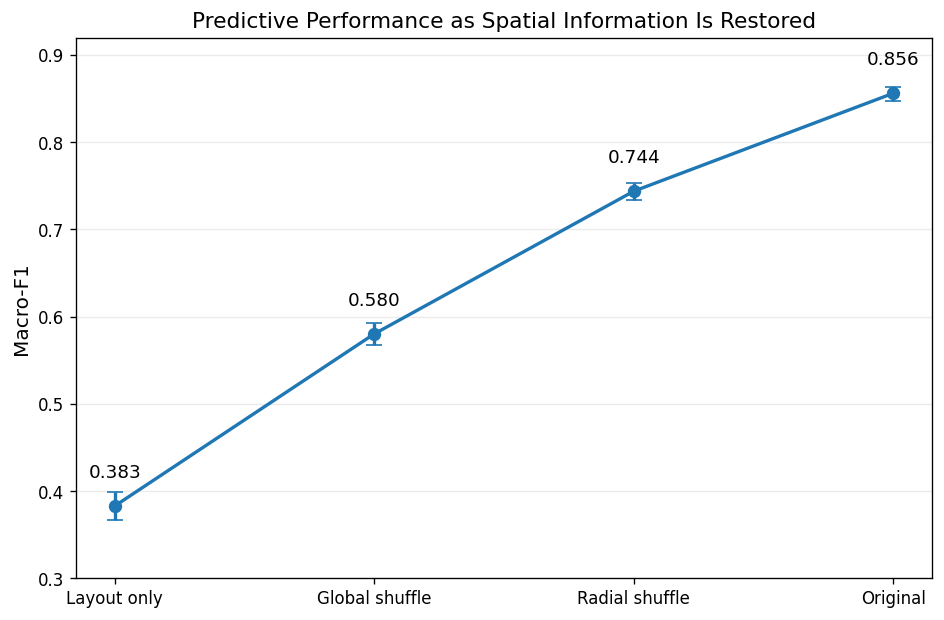

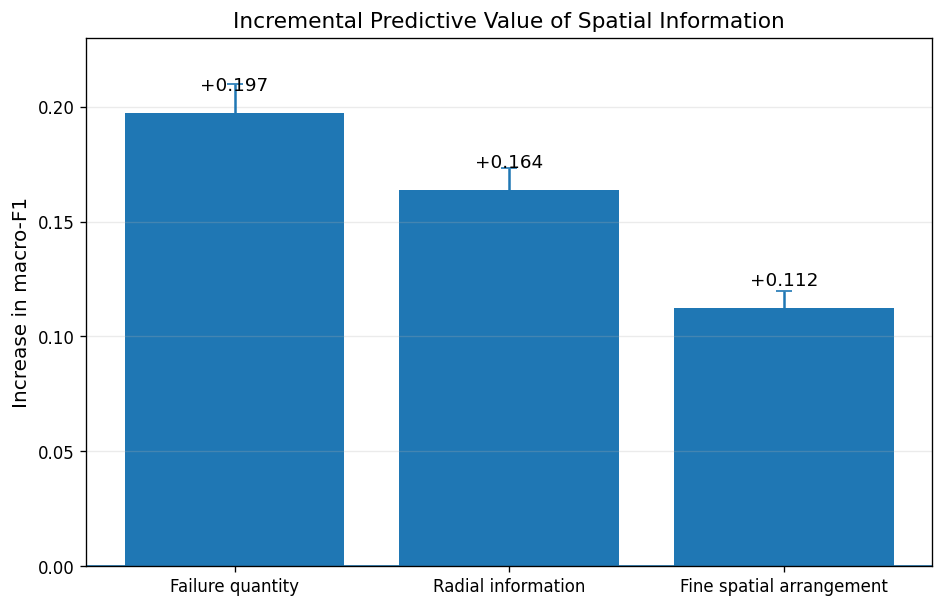

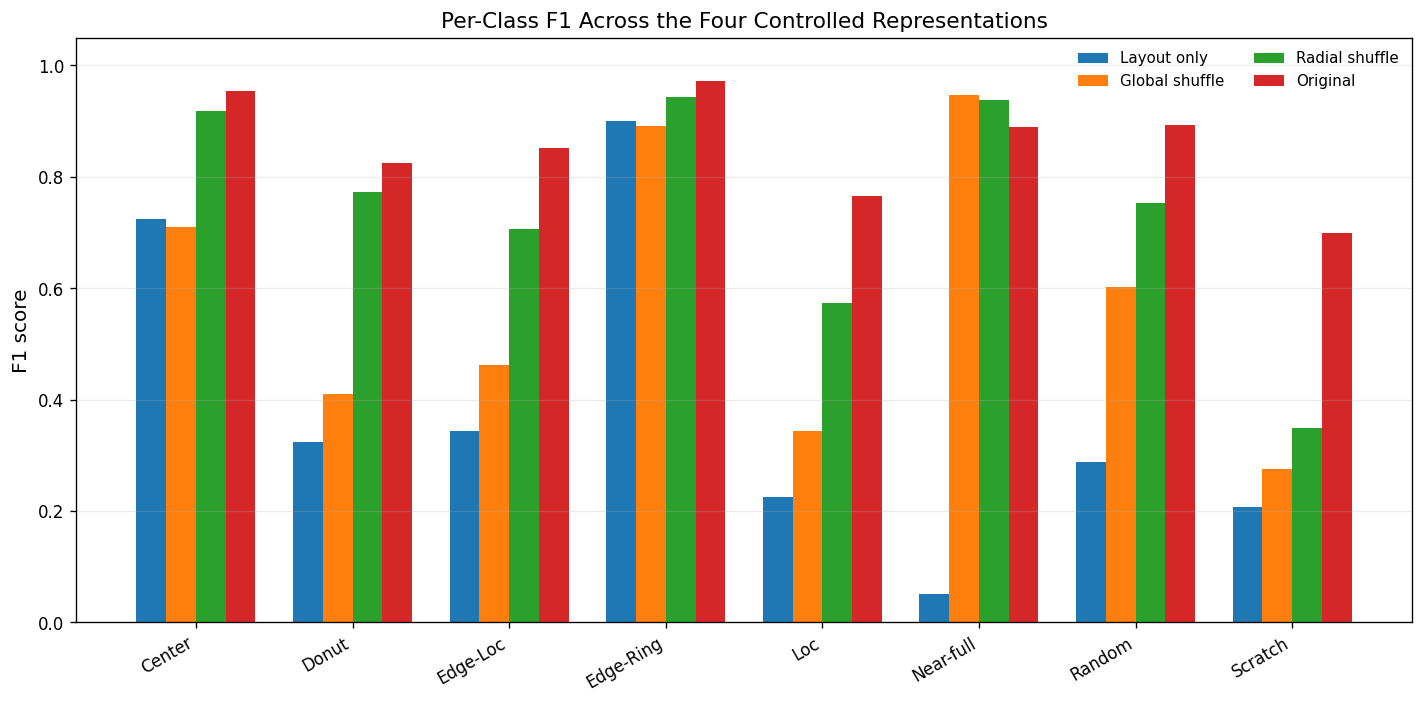

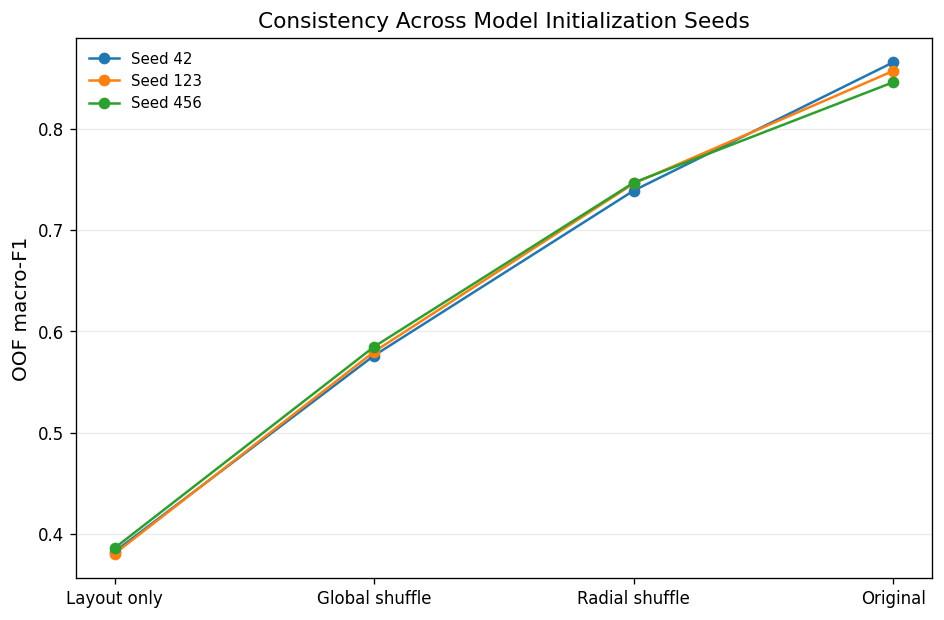


TABLE 1 — PRIMARY PERFORMANCE


,Representation,Macro-F1,Macro-F1 95% CI lower,Macro-F1 95% CI upper,Balanced accuracy,Accuracy
0,Layout only,0.3829,0.3664,0.3987,0.4713,0.5518
1,Global shuffle,0.5803,0.5672,0.5925,0.6101,0.6363
2,Radial shuffle,0.7439,0.7344,0.7528,0.7639,0.7925
3,Original,0.8563,0.8475,0.8636,0.8665,0.8953



TABLE 2 — INFORMATION-STEP GAINS


,Information added,Macro-F1 gain,95% CI lower,95% CI upper
0,Failure quantity,0.1974,0.1860,0.2097
4,Radial information,0.1636,0.1551,0.1731
8,Fine spatial arrangement,0.1123,0.1049,0.1199



TABLE 3 — PER-CLASS F1


,Defect class,Layout only,Global shuffle,Radial shuffle,Original
0,Center,0.723,0.710,0.917,0.955
1,Donut,0.325,0.409,0.773,0.825
2,Edge-Loc,0.344,0.462,0.706,0.851
3,Edge-Ring,0.900,0.892,0.943,0.972
4,Loc,0.225,0.343,0.573,0.766
5,Near-full,0.051,0.948,0.938,0.889
6,Random,0.287,0.602,0.754,0.893
7,Scratch,0.207,0.276,0.348,0.699



PAPER OUTPUT GENERATION COMPLETE

Figures:
/content/drive/MyDrive/WM811K_Spatial_Information_Audit/paper_outputs/figures

Tables:
/content/drive/MyDrive/WM811K_Spatial_Information_Audit/paper_outputs/tables

Created:
  Figure 1  - Macro-F1 progression
  Figure 2  - Information-step gains
  Figure 3  - Per-class F1
  Figure S1 - Seed consistency
  Table 1   - Primary performance
  Table 2   - Information-step gains
  Table 3   - Per-class F1

No training occurred.
No frozen scientific protocol was changed.


In [ ]:
# ============================================================
# CELL 5 — PAPER-READY FIGURES AND TABLES
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# PATHS
# ============================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/WM811K_Spatial_Information_Audit"
)

PRIMARY_RUNS_DIR = (
    PROJECT_ROOT
    / "experiments"
    / "primary_runs"
)

AGGREGATE_DIR = (
    PRIMARY_RUNS_DIR
    / "aggregate_all_representations"
)

STATS_DIR = (
    PRIMARY_RUNS_DIR
    / "final_statistics"
)

PAPER_DIR = (
    PROJECT_ROOT
    / "paper_outputs"
)

FIGURE_DIR = (
    PAPER_DIR
    / "figures"
)

TABLE_DIR = (
    PAPER_DIR
    / "tables"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# LOAD FROZEN RESULTS
# ============================================================

performance_ci = pd.read_csv(
    STATS_DIR
    / "cluster_bootstrap_representation_performance.csv"
)

delta_ci = pd.read_csv(
    STATS_DIR
    / "cluster_bootstrap_information_step_deltas.csv"
)

per_class = pd.read_csv(
    AGGREGATE_DIR
    / "per_class_oof_summary.csv"
)

pooled_seed = pd.read_csv(
    AGGREGATE_DIR
    / "pooled_oof_by_representation_and_seed.csv"
)


REP_ORDER = [
    "layout_only",
    "global_shuffle",
    "radial_shuffle",
    "original",
]

REP_LABELS = {
    "layout_only": "Layout only",
    "global_shuffle": "Global shuffle",
    "radial_shuffle": "Radial shuffle",
    "original": "Original",
}

STEP_ORDER = [
    "layout_to_global",
    "global_to_radial",
    "radial_to_original",
]

STEP_LABELS = {
    "layout_to_global":
        "Failure quantity",

    "global_to_radial":
        "Radial information",

    "radial_to_original":
        "Fine spatial arrangement",
}


# ============================================================
# GENERAL FIGURE SETTINGS
# ============================================================

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,
    "figure.dpi": 120,
})


# ============================================================
# FIGURE 1
# PRIMARY MACRO-F1 PROGRESSION WITH 95% CI
# ============================================================

macro = (
    performance_ci[
        performance_ci["metric"] == "macro_f1"
    ]
    .set_index("representation")
    .loc[REP_ORDER]
    .reset_index()
)

x = np.arange(len(REP_ORDER))

y = macro["point_estimate"].to_numpy()

lower = (
    y
    -
    macro["ci95_lower"].to_numpy()
)

upper = (
    macro["ci95_upper"].to_numpy()
    -
    y
)

fig, ax = plt.subplots(
    figsize=(8, 5.3)
)

ax.errorbar(
    x,
    y,
    yerr=[lower, upper],
    fmt="o-",
    linewidth=2,
    markersize=7,
    capsize=5,
)

ax.set_xticks(x)

ax.set_xticklabels(
    [
        REP_LABELS[r]
        for r in REP_ORDER
    ]
)

ax.set_ylabel(
    "Macro-F1"
)

ax.set_title(
    "Predictive Performance as Spatial Information Is Restored"
)

ax.set_ylim(
    0.30,
    0.92
)

ax.grid(
    axis="y",
    alpha=0.25
)

for xi, yi in zip(x, y):

    ax.text(
        xi,
        yi + 0.028,
        f"{yi:.3f}",
        ha="center",
        va="bottom",
    )

fig.tight_layout()

fig.savefig(
    FIGURE_DIR
    / "Figure_1_macro_f1_progression.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_DIR
    / "Figure_1_macro_f1_progression.pdf",
    bbox_inches="tight",
)

plt.show()


# ============================================================
# FIGURE 2
# INFORMATION-STEP GAINS WITH 95% CI
# ============================================================

step = (
    delta_ci[
        delta_ci["metric"] == "macro_f1"
    ]
    .set_index("comparison")
    .loc[STEP_ORDER]
    .reset_index()
)

x = np.arange(
    len(STEP_ORDER)
)

y = step[
    "point_delta"
].to_numpy()

lower = (
    y
    -
    step[
        "ci95_lower"
    ].to_numpy()
)

upper = (
    step[
        "ci95_upper"
    ].to_numpy()
    -
    y
)

fig, ax = plt.subplots(
    figsize=(8, 5.2)
)

bars = ax.bar(
    x,
    y,
)

ax.errorbar(
    x,
    y,
    yerr=[lower, upper],
    fmt="none",
    capsize=5,
    linewidth=1.5,
)

ax.axhline(
    0,
    linewidth=1
)

ax.set_xticks(x)

ax.set_xticklabels(
    [
        STEP_LABELS[s]
        for s in STEP_ORDER
    ]
)

ax.set_ylabel(
    "Increase in macro-F1"
)

ax.set_title(
    "Incremental Predictive Value of Spatial Information"
)

ax.set_ylim(
    0,
    0.23
)

ax.grid(
    axis="y",
    alpha=0.25
)

for xi, yi in zip(x, y):

    ax.text(
        xi,
        yi + 0.008,
        f"+{yi:.3f}",
        ha="center",
        va="bottom",
    )

fig.tight_layout()

fig.savefig(
    FIGURE_DIR
    / "Figure_2_information_step_gains.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_DIR
    / "Figure_2_information_step_gains.pdf",
    bbox_inches="tight",
)

plt.show()


# ============================================================
# FIGURE 3
# PER-CLASS F1 ACROSS REPRESENTATIONS
# ============================================================

class_order = (
    per_class[
        per_class[
            "representation"
        ]
        ==
        "original"
    ]
    .sort_values(
        "class_id"
    )[
        "label"
    ]
    .tolist()
)

pivot = (
    per_class
    .pivot(
        index="label",
        columns="representation",
        values="mean_f1",
    )
    .loc[
        class_order,
        REP_ORDER,
    ]
)

n_classes = len(
    pivot
)

n_reps = len(
    REP_ORDER
)

x = np.arange(
    n_classes
)

width = 0.19

fig, ax = plt.subplots(
    figsize=(12, 6)
)

for i, representation in enumerate(
    REP_ORDER
):

    offset = (
        i
        -
        (n_reps - 1) / 2
    ) * width

    ax.bar(
        x + offset,
        pivot[
            representation
        ].to_numpy(),
        width,
        label=REP_LABELS[
            representation
        ],
    )

ax.set_xticks(
    x
)

ax.set_xticklabels(
    class_order,
    rotation=30,
    ha="right",
)

ax.set_ylabel(
    "F1 score"
)

ax.set_title(
    "Per-Class F1 Across the Four Controlled Representations"
)

ax.set_ylim(
    0,
    1.05
)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.legend(
    ncol=2,
    frameon=False,
)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR
    / "Figure_3_per_class_f1.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_DIR
    / "Figure_3_per_class_f1.pdf",
    bbox_inches="tight",
)

plt.show()


# ============================================================
# FIGURE S1
# SEED CONSISTENCY
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 5.3)
)

for seed in sorted(
    pooled_seed[
        "model_seed"
    ].unique()
):

    subset = (
        pooled_seed[
            pooled_seed[
                "model_seed"
            ]
            ==
            seed
        ]
        .set_index(
            "representation"
        )
        .loc[
            REP_ORDER
        ]
    )

    ax.plot(
        np.arange(
            len(
                REP_ORDER
            )
        ),
        subset[
            "oof_macro_f1"
        ],
        marker="o",
        label=f"Seed {seed}",
    )

ax.set_xticks(
    np.arange(
        len(
            REP_ORDER
        )
    )
)

ax.set_xticklabels(
    [
        REP_LABELS[r]
        for r in REP_ORDER
    ]
)

ax.set_ylabel(
    "OOF macro-F1"
)

ax.set_title(
    "Consistency Across Model Initialization Seeds"
)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.legend(
    frameon=False
)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR
    / "Figure_S1_seed_consistency.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_DIR
    / "Figure_S1_seed_consistency.pdf",
    bbox_inches="tight",
)

plt.show()


# ============================================================
# TABLE 1
# PRIMARY PERFORMANCE
# ============================================================

table1_rows = []

for representation in REP_ORDER:

    macro_row = performance_ci[
        (
            performance_ci[
                "representation"
            ]
            ==
            representation
        )
        &
        (
            performance_ci[
                "metric"
            ]
            ==
            "macro_f1"
        )
    ].iloc[0]

    ba_row = performance_ci[
        (
            performance_ci[
                "representation"
            ]
            ==
            representation
        )
        &
        (
            performance_ci[
                "metric"
            ]
            ==
            "balanced_accuracy"
        )
    ].iloc[0]

    acc_row = performance_ci[
        (
            performance_ci[
                "representation"
            ]
            ==
            representation
        )
        &
        (
            performance_ci[
                "metric"
            ]
            ==
            "accuracy"
        )
    ].iloc[0]

    table1_rows.append({
        "Representation":
            REP_LABELS[
                representation
            ],

        "Macro-F1":
            macro_row[
                "point_estimate"
            ],

        "Macro-F1 95% CI lower":
            macro_row[
                "ci95_lower"
            ],

        "Macro-F1 95% CI upper":
            macro_row[
                "ci95_upper"
            ],

        "Balanced accuracy":
            ba_row[
                "point_estimate"
            ],

        "Accuracy":
            acc_row[
                "point_estimate"
            ],
    })


table1 = pd.DataFrame(
    table1_rows
)

table1.to_csv(
    TABLE_DIR
    / "Table_1_primary_performance.csv",
    index=False,
)


print()
print("=" * 80)
print("TABLE 1 — PRIMARY PERFORMANCE")
print("=" * 80)

display(
    table1.round(4)
)


# ============================================================
# TABLE 2
# INFORMATION-STEP GAINS
# ============================================================

table2 = (
    delta_ci[
        (
            delta_ci[
                "metric"
            ]
            ==
            "macro_f1"
        )
        &
        (
            delta_ci[
                "comparison"
            ]
            .isin(
                STEP_ORDER
            )
        )
    ][
        [
            "comparison",
            "point_delta",
            "ci95_lower",
            "ci95_upper",
        ]
    ]
    .copy()
)

table2["Information added"] = (
    table2[
        "comparison"
    ]
    .map(
        STEP_LABELS
    )
)

table2 = table2[
    [
        "Information added",
        "point_delta",
        "ci95_lower",
        "ci95_upper",
    ]
]

table2.columns = [
    "Information added",
    "Macro-F1 gain",
    "95% CI lower",
    "95% CI upper",
]

table2.to_csv(
    TABLE_DIR
    / "Table_2_information_step_gains.csv",
    index=False,
)


print()
print("=" * 80)
print("TABLE 2 — INFORMATION-STEP GAINS")
print("=" * 80)

display(
    table2.round(4)
)


# ============================================================
# TABLE 3
# PER-CLASS F1
# ============================================================

table3 = (
    pivot
    .copy()
    .reset_index()
)

table3.columns = [
    "Defect class",
    "Layout only",
    "Global shuffle",
    "Radial shuffle",
    "Original",
]

table3.to_csv(
    TABLE_DIR
    / "Table_3_per_class_f1.csv",
    index=False,
)


print()
print("=" * 80)
print("TABLE 3 — PER-CLASS F1")
print("=" * 80)

display(
    table3.round(3)
)


# ============================================================
# FINAL SUMMARY
# ============================================================

print()
print("=" * 80)
print("PAPER OUTPUT GENERATION COMPLETE")
print("=" * 80)

print()
print("Figures:")
print(FIGURE_DIR)

print()
print("Tables:")
print(TABLE_DIR)

print()
print("Created:")
print("  Figure 1  - Macro-F1 progression")
print("  Figure 2  - Information-step gains")
print("  Figure 3  - Per-class F1")
print("  Figure S1 - Seed consistency")
print("  Table 1   - Primary performance")
print("  Table 2   - Information-step gains")
print("  Table 3   - Per-class F1")

print()
print("No training occurred.")
print("No frozen scientific protocol was changed.")

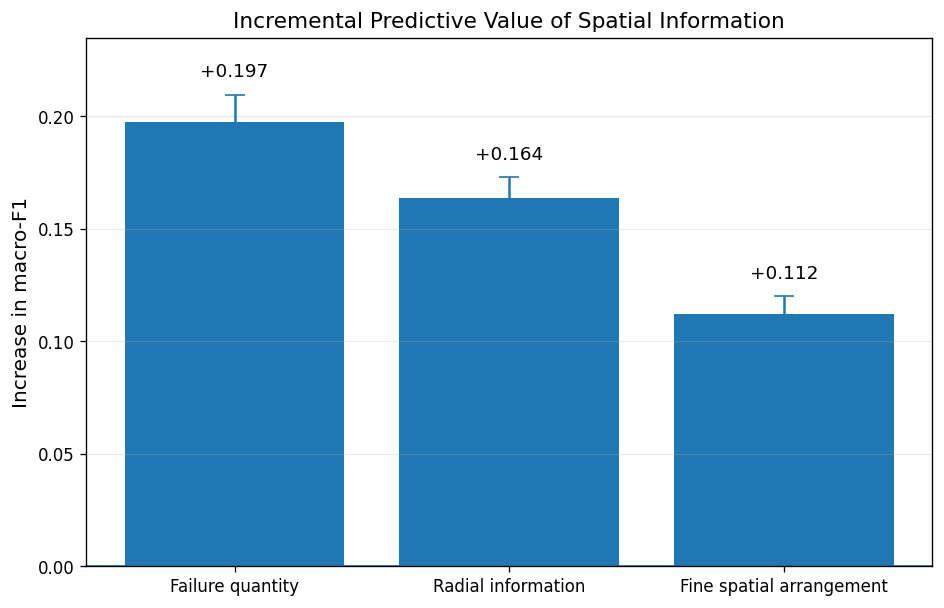


Regenerated Figure 2:
/content/drive/MyDrive/WM811K_Spatial_Information_Audit/paper_outputs/figures/Figure_2_information_step_gains.png
/content/drive/MyDrive/WM811K_Spatial_Information_Audit/paper_outputs/figures/Figure_2_information_step_gains.pdf


In [ ]:
# ============================================================
# REGENERATE FIGURE 2 ONLY — FIX LABEL / WHISKER OVERLAP
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/WM811K_Spatial_Information_Audit"
)

STATS_DIR = (
    PROJECT_ROOT
    / "experiments"
    / "primary_runs"
    / "final_statistics"
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "paper_outputs"
    / "figures"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Load frozen bootstrap results
# ------------------------------------------------------------

delta_ci = pd.read_csv(
    STATS_DIR
    / "cluster_bootstrap_information_step_deltas.csv"
)


STEP_ORDER = [
    "layout_to_global",
    "global_to_radial",
    "radial_to_original",
]

STEP_LABELS = {
    "layout_to_global":
        "Failure quantity",

    "global_to_radial":
        "Radial information",

    "radial_to_original":
        "Fine spatial arrangement",
}


step = (
    delta_ci[
        delta_ci["metric"] == "macro_f1"
    ]
    .set_index("comparison")
    .loc[STEP_ORDER]
    .reset_index()
)


# ------------------------------------------------------------
# Values and confidence intervals
# ------------------------------------------------------------

x = np.arange(
    len(STEP_ORDER)
)

y = step[
    "point_delta"
].to_numpy()

ci_lower = step[
    "ci95_lower"
].to_numpy()

ci_upper = step[
    "ci95_upper"
].to_numpy()

lower_error = (
    y - ci_lower
)

upper_error = (
    ci_upper - y
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})


fig, ax = plt.subplots(
    figsize=(8, 5.2)
)


ax.bar(
    x,
    y,
)


ax.errorbar(
    x,
    y,
    yerr=[
        lower_error,
        upper_error
    ],
    fmt="none",
    capsize=6,
    linewidth=1.5,
)


ax.axhline(
    0,
    linewidth=1
)


ax.set_xticks(
    x
)

ax.set_xticklabels(
    [
        STEP_LABELS[s]
        for s in STEP_ORDER
    ]
)


ax.set_ylabel(
    "Increase in macro-F1"
)

ax.set_title(
    "Incremental Predictive Value of Spatial Information"
)


# Give the labels more room above the whiskers
ax.set_ylim(
    0,
    0.235
)


ax.grid(
    axis="y",
    alpha=0.25
)


# ------------------------------------------------------------
# Put each number ABOVE the CI whisker
# ------------------------------------------------------------

LABEL_GAP = 0.006

for xi, yi, upper_ci in zip(
    x,
    y,
    ci_upper
):

    ax.text(
        xi,
        upper_ci + LABEL_GAP,
        f"+{yi:.3f}",
        ha="center",
        va="bottom",
        fontsize=11,
    )


fig.tight_layout()


# ------------------------------------------------------------
# Save to SAME locations as before
# ------------------------------------------------------------

png_path = (
    FIGURE_DIR
    / "Figure_2_information_step_gains.png"
)

pdf_path = (
    FIGURE_DIR
    / "Figure_2_information_step_gains.pdf"
)


fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
)


plt.show()


print()
print("Regenerated Figure 2:")
print(png_path)
print(pdf_path)